# Landsat-sharpened CLMS Land Surface Temperature: method, validation and error budget

[![DOI](https://zenodo.org/badge/DOI/10.5281/zenodo.22944002.svg)](https://doi.org/10.5281/zenodo.22944002)

**Author:** András Zlinszky (Sinergise Solutions, Graz, Austria; ORCID [0000-0002-9717-0043](https://orcid.org/0000-0002-9717-0043)) · **Version:** 1.0 Please note that AI (Claud Code with Opus 5.5 Medium model) was used extensively for the preparation of this notebook and its companion evalscript. The text was edited and proofread manually and the evalscript was tested manually in Copernicus Browser.



The Copernicus Land Monitoring Service (CLMS) publishes global Land Surface Temperature (LST) every hour, but at 3 km resolution - a whole city covers only a handful of pixels. Landsat 8-9 resolves LST at ~100 m, but revisits every 8-16 days and only sees the surface when the sky is clear. This notebook presents and evaluates a simple way to combine the two: the **fine-scale spatial pattern** of Landsat LST, measured on one clear-sky calibration date, is added to CLMS LST for any other date and hour.

```
residual      = LST_Landsat_cal - LST_CLMS_cal      (fine-scale correction field)
LST_sharpened = LST_CLMS_target + residual + bias_offset
```

The method rests on one assumption: the fine-scale spatial structure of urban LST anomalies (street canyons, parks, water, industrial roofs) is approximately stable in time. The notebook is organised like a short paper that tests this assumption and quantifies the resulting error:

| Part | Question | Cost |
| --- | --- | --- |
| **1. Quick look** (Section 2) | What does the method do? One sharpened map over Budapest. | 1 request |
| **2. One city** (Sections 3-8) | Is the residual field stable in time over Budapest? | ~15 requests |
| **3. Portability** (Sections 9-10) | Does the method, and its bias term, travel between climate zones? | ~200 requests |
| **4. Model adequacy** (Section 11) | Is an *additive* correction the right model? | ~65 PU for one sweep, otherwise free |
| **5. Error budget** (Sections 12-14) | How accurate is a sharpened map, and compared to what? | free (reuses fetched data) |

If you only want to understand the approach, run the Setup and Part 1 and stop there.

**Companion custom script.** The same sharpening runs interactively in the Copernicus Browser with the [`clms_lst_sharpening_with_landsat`](https://custom-scripts.sentinel-hub.com/data-fusion/clms_lst_sharpening_with_landsat/) custom script, which is the right tool for *looking at* a sharpened scene. What the Browser cannot do is stack many dates and reduce them to statistics - which Parts 2-5 need, and which the Process API provides.

**Prerequisites:** the CDSE JupyterLab `Sentinel Hub` kernel and Sentinel Hub credentials (prompted for below if not already configured). No local files are needed.

**How to cite:** see [How to cite](#How-to-cite) at the end of the notebook.

*Contains modified Copernicus Land Monitoring Service information (2022-2026). Landsat data courtesy of the U.S. Geological Survey.*

In [1]:
# Utilities
import getpass
from datetime import timedelta

import numpy as np
import matplotlib.pyplot as plt
from dateutil import parser as dtparser
from shapely.geometry import shape, box

from sentinelhub import (
    SHConfig,
    DataCollection,
    SentinelHubCatalog,
    SentinelHubRequest,
    BBox,
    bbox_to_dimensions,
    CRS,
    MimeType,
)

## 1. Setup

### 1.1 Credentials

Sentinel Hub credentials may already be configured on CDSE. If they are not, you are prompted for them; they are kept in memory only and never written to the notebook. The configuration is then pointed at the CDSE endpoints.

In [2]:
config = SHConfig()
if not (config.sh_client_id and config.sh_client_secret):
    config.sh_client_id = getpass.getpass("Enter your SentinelHub client id")
    config.sh_client_secret = getpass.getpass("Enter your SentinelHub client secret")
config.sh_token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
config.sh_base_url = "https://sh.dataspace.copernicus.eu"

Enter your SentinelHub client id ········
Enter your SentinelHub client secret ········


### 1.2 Data collections

Two collections are used, both served by the CDSE Sentinel Hub endpoint:

- **Landsat 8-9 Collection 2 Level-1** (`LANDSAT_OT_L1`). Band `B10` is delivered as top-of-atmosphere brightness temperature in Kelvin, `B04`/`B05` give the NDVI for the emissivity model, and `BQA` carries the per-pixel cloud flags.
- **CLMS LST 3 km hourly V3**, a BYOC collection referenced by its [collection ID](https://documentation.dataspace.copernicus.eu/APIs/SentinelHub/Data/clms/bio-geophysical-parameters/temperature-and-reflectance/land-surface-temperature/lst_global_3km_hourly_v3.html). Raw values decode to Kelvin as `LST * 0.01 + 273.15`.

The Catalog API client is used later to search for clear-sky Landsat scenes.

In [3]:
CDSE_URL = "https://sh.dataspace.copernicus.eu"
CLMS_LST_ID = "12225aec-26dd-4e2c-bbfd-994c253c1ba8"  # CLMS LST 3 km hourly V3

landsat = DataCollection.LANDSAT_OT_L1.define_from("l8_cdse", service_url=CDSE_URL)
clms = DataCollection.define_byoc(CLMS_LST_ID, service_url=CDSE_URL)
catalog = SentinelHubCatalog(config=config)

# Part 1 - Quick look

## 2. Sharpening one CLMS scene over Budapest

This part runs the sharpening once, the way the companion custom script does in the Copernicus Browser: one clear-sky Landsat overpass for calibration, the CLMS slot matching that overpass, and a target CLMS hour to be sharpened.

### 2.1 Parameters

The defaults reproduce the example of the custom script: calibration on the Landsat overpass of 13 June 2025 (09:32:47 UTC), and a target hour of 09:00 UTC on 10 August 2026, a heatwave morning in Budapest. Change them to sharpen another hour or another place. The calibration time must be the exact sensing time of a clear-sky Landsat scene (listed by the Catalog search in Section 3.3, or shown in the Copernicus Browser).

In [4]:
# Budapest metro area [min_lon, min_lat, max_lon, max_lat]
AOI_BBOX = [18.95, 47.40, 19.20, 47.60]
RESOLUTION = 100  # m, native Landsat TIRS resolution

# Calibration: sensing time (UTC) of a clear-sky Landsat 8-9 overpass
QL_LANDSAT_TIME = "2025-06-13T09:32:47Z"

# Target: the CLMS hour to sharpen, normally the same hour of day as the overpass
QL_TARGET_TIME = "2026-08-10T09:00:00Z"

bbox = BBox(bbox=AOI_BBOX, crs=CRS.WGS84)
size = bbox_to_dimensions(bbox, resolution=RESOLUTION)
print("Output size (px):", size)

Output size (px): (194, 218)


### 2.2 Matching Landsat and CLMS in time

Every request needs one time window per data source:

- **Landsat:** a narrow window around the overpass, so that exactly one scene is selected.
- **CLMS:** the hourly slot *containing* the Landsat overpass - for a 09:32 overpass, the 09:00 slot. The residual is the difference between two supposedly simultaneous observations, so any time gap between them puts real thermal change into it. This is the same rule the custom script documents for its `CLMS_CAL` layer.

The same helper selects the target CLMS hour.

In [5]:
TIME_FMT = "%Y-%m-%dT%H:%M:%SZ"


def landsat_window(iso_time, half_width=timedelta(minutes=30)):
    """Narrow window around a Landsat overpass, so that exactly one scene is used."""
    t = dtparser.isoparse(iso_time)
    return ((t - half_width).strftime(TIME_FMT), (t + half_width).strftime(TIME_FMT))


def clms_window(iso_time):
    """The CLMS hourly slot containing iso_time, e.g. 09:32 -> 09:00:00-09:59:59."""
    t = dtparser.isoparse(iso_time).replace(minute=0, second=0, microsecond=0)
    end = t + timedelta(minutes=59, seconds=59)
    return (t.strftime(TIME_FMT), end.strftime(TIME_FMT))


print("Calibration Landsat window:", landsat_window(QL_LANDSAT_TIME))
print("Calibration CLMS slot:     ", clms_window(QL_LANDSAT_TIME))
print("Target CLMS slot:          ", clms_window(QL_TARGET_TIME))

Calibration Landsat window: ('2025-06-13T09:02:47Z', '2025-06-13T10:02:47Z')
Calibration CLMS slot:      ('2025-06-13T09:00:00Z', '2025-06-13T09:59:59Z')
Target CLMS slot:           ('2026-08-10T09:00:00Z', '2026-08-10T09:59:59Z')


### 2.3 Landsat LST retrieval

Landsat LST is derived with the single-channel method of the [Landsat-8 LST mapping custom script](https://custom-scripts.sentinel-hub.com/landsat-8/land_surface_temperature_mapping/) (M. Gartner). NDVI classifies each pixel as water, bare soil, full vegetation or a mixture; the emissivity of mixed pixels is interpolated using the proportional vegetation cover `Pv` (Carlson & Ripley, 1997); and the `B10` brightness temperature is converted to LST with that emissivity (Artis & Carnahan, 1982).

- **Emissivity endmembers** water 0.991 / soil 0.966 / vegetation 0.973 are taken from Wang et al. (2015), Table 8. The NDVI thresholds are `NDVIs = 0.2` (Sobrino & Raissouni, 2000) and `NDVIv = 0.8` (Jiménez-Muñoz et al., 2009).
- **Roughness constant `C`.** For mixed soil/vegetation pixels `LSE = eps_veg * Pv + eps_soil * (1 - Pv) + C`, where `C` accounts for the cavity effect of surface roughness. We use `C = 0.005` after Sobrino et al. (2008) and Avdan & Jovanovska (2016). Some Landsat LST scripts use 0.009, a value we could not trace to a primary measurement; the difference is ~0.2-0.3 K on mixed soil/vegetation pixels. Other (pure) pixels are unaffected
- **Cloud mask.** Pixels flagged in the Landsat Collection 2 quality band (`decodeL8C2Qa` on `BQA`: fill, cloud, dilated cloud, cirrus, shadow) are masked. So are pixels whose LST falls outside -20...+60 °C.

The JavaScript below is shared by every evalscript in this notebook, so all parts use exactly the same retrieval. Its constants are identical to those of the companion custom scripts. The per-pixel cloud mask matches their `bias_offset.js` and `landsat_lst_reference.js`; the Browser's `script.js` itself has no cloud mask.

Note that this is **top-of-atmosphere** LST: no atmospheric correction is applied, so it reads several Kelvin colder than the atmospherically corrected CLMS product. `bias_offset` removes that offset, which is studied in Parts 2-3.

In [6]:
LANDSAT_LST_JS = """
// Landsat 8-9 L1 land surface temperature, shared by all evalscripts below.
// Constants are identical to the companion custom scripts.
const NDVIs = 0.2, NDVIv = 0.8;  // NDVI of bare soil / full vegetation
const waterE = 0.991, soilE = 0.966, vegetationE = 0.973;  // emissivity endmembers
const C = 0.005;  // surface roughness term (Sobrino et al. 2008)
const bCent = 0.000010895;  // B10 central wavelength (m)
const rho = 0.01438;  // h * c / k_B (m K)
const minValidC = -20, maxValidC = 60;  // physical sanity range (degC)
const CLMS_FACTOR = 1 / 100, CLMS_OFFSET = 273.15;  // raw CLMS LST -> Kelvin

function LSEcalc(NDVI, Pv) {
  if (NDVI < 0) return waterE;
  if (NDVI < NDVIs) return soilE;
  if (NDVI > NDVIv) return vegetationE;
  return vegetationE * Pv + soilE * (1 - Pv) + C;  // soil/vegetation mixture
}

// LST in Kelvin, or null for cloud, fill or physically implausible pixels
function landsatLST(s) {
  var qa = decodeL8C2Qa(s.BQA);
  if (qa.fill || qa.cloud || qa.dilatedCloud || qa.cirrus || qa.cloudShadow) return null;
  if (!(s.B10 > 173 && s.B10 < 65000 && s.B03 > 0 && s.B04 > 0 && s.B05 > 0)) return null;
  var btC = s.B10 - 273.15;  // brightness temperature, degC
  var NDVI = (s.B05 - s.B04) / (s.B05 + s.B04);
  var Pv = Math.pow((NDVI - NDVIs) / (NDVIv - NDVIs), 2);  // proportional vegetation
  var lstC = btC / (1 + ((bCent * btC) / rho) * Math.log(LSEcalc(NDVI, Pv)));
  if (lstC < minValidC || lstC > maxValidC) return null;
  return lstC + 273.15;
}
"""

### 2.4 The sharpening evalscript

A data-fusion evalscript with three inputs: the Landsat calibration scene (`LANDSAT-OT-L1`), the CLMS slot matching it (`CLMS_CAL`) and the CLMS target hour (`CLMS_TGT`). The CLMS collection is added twice with different time windows, which lets one request see both the calibration field and the target field.

For each pixel it computes the residual and the sharpened LST with `bias_offset = 0`. The offset is added in Python in the next step, because it depends on the scene mean of the residual, which a per-pixel evalscript cannot compute. The calibration ingredients are returned alongside the sharpened LST, for plotting.

In [7]:
SHARPEN_JS = """
function setup() {
  return {
    input: [
      { datasource: "LANDSAT-OT-L1", bands: ["B03", "B04", "B05", "B10", "BQA"] },
      { datasource: "CLMS_CAL", bands: ["LST", "dataMask"] },
      { datasource: "CLMS_TGT", bands: ["LST", "dataMask"] },
    ],
    output: [
      { id: "sharpened", bands: 1, sampleType: "FLOAT32" },
      { id: "residual", bands: 1, sampleType: "FLOAT32" },
      { id: "landsat_lst", bands: 1, sampleType: "FLOAT32" },
      { id: "clms_tgt", bands: 1, sampleType: "FLOAT32" },
    ],
    mosaicking: "SIMPLE",
  };
}

function evaluatePixel(samples) {
  var clmsCal = samples.CLMS_CAL[0];
  var clmsTgt = samples.CLMS_TGT[0];
  var lstClmsTgt = clmsTgt.dataMask ? clmsTgt.LST * CLMS_FACTOR + CLMS_OFFSET : NaN;
  var lstLandsatCal = landsatLST(samples["LANDSAT-OT-L1"][0]);
  if (!clmsCal.dataMask || lstLandsatCal === null) {
    return { sharpened: [NaN], residual: [NaN], landsat_lst: [NaN], clms_tgt: [lstClmsTgt] };
  }
  var residual = lstLandsatCal - (clmsCal.LST * CLMS_FACTOR + CLMS_OFFSET);
  return {
    sharpened: [lstClmsTgt + residual],  // bias_offset = 0, added in Python
    residual: [residual],
    landsat_lst: [lstLandsatCal],
    clms_tgt: [lstClmsTgt],
  };
}
"""

sharpen_evalscript = "//VERSION=3\n" + LANDSAT_LST_JS + SHARPEN_JS

### 2.5 Request

`fetch_outputs()` wraps one Process API request with several named FLOAT32 outputs and returns them as float64 arrays. The function is reused throughout the notebook.

In [8]:
def fetch_outputs(evalscript, inputs, output_ids, request_bbox, request_size):
    """Run one Process API request and return {output id: float64 array}.

    inputs is a list of (datasource alias, collection, time window) tuples.
    """
    request = SentinelHubRequest(
        evalscript=evalscript,
        input_data=[
            SentinelHubRequest.input_data(
                data_collection=collection, identifier=alias, time_interval=window
            )
            for alias, collection, window in inputs
        ],
        responses=[
            SentinelHubRequest.output_response(oid, MimeType.TIFF) for oid in output_ids
        ],
        bbox=request_bbox,
        size=request_size,
        config=config,
    )
    data = request.get_data()[0]
    return {oid: data[f"{oid}.tif"].astype(np.float64) for oid in output_ids}

We run the request over Budapest at 100 m and then set `bias_offset = -mean(residual)`. This anchors the scene mean of the sharpened map to CLMS: CLMS is treated as the reference for absolute temperature, and Landsat as the source of spatial detail only. In the Copernicus Browser, the same number is measured with the companion `bias_offset.js` script.

In [9]:
quick = fetch_outputs(
    sharpen_evalscript,
    [
        ("LANDSAT-OT-L1", landsat, landsat_window(QL_LANDSAT_TIME)),
        ("CLMS_CAL", clms, clms_window(QL_LANDSAT_TIME)),
        ("CLMS_TGT", clms, clms_window(QL_TARGET_TIME)),
    ],
    ["sharpened", "residual", "landsat_lst", "clms_tgt"],
    bbox,
    size,
)
if not np.isfinite(quick["residual"]).any():
    raise ValueError(
        "No valid calibration pixels - check that QL_LANDSAT_TIME is the sensing "
        "time of a clear-sky Landsat scene."
    )

# bias_offset = -mean(residual) anchors the sharpened scene mean to CLMS
ql_bias_offset = -float(np.nanmean(quick["residual"]))
quick["sharpened"] = quick["sharpened"] + ql_bias_offset

print(f"Valid calibration pixels: {np.isfinite(quick['residual']).mean():.0%}")
print(f"bias_offset from this calibration pair: {ql_bias_offset:+.2f} K")
print(f"Spatial std dev, native CLMS target: {np.nanstd(quick['clms_tgt']):.2f} K")
print(f"Spatial std dev, sharpened target:   {np.nanstd(quick['sharpened']):.2f} K")

Valid calibration pixels: 100%
bias_offset from this calibration pair: +2.23 K
Spatial std dev, native CLMS target: 2.00 K
Spatial std dev, sharpened target:   3.94 K


### 2.6 Result

The top row compares the native CLMS field for the target hour with its sharpened version, on a shared colour scale. The bottom row shows the two ingredients from the calibration date: the Landsat LST, and the correction field that was added to CLMS. The correction field is the residual plus `bias_offset`, so it averages to zero.

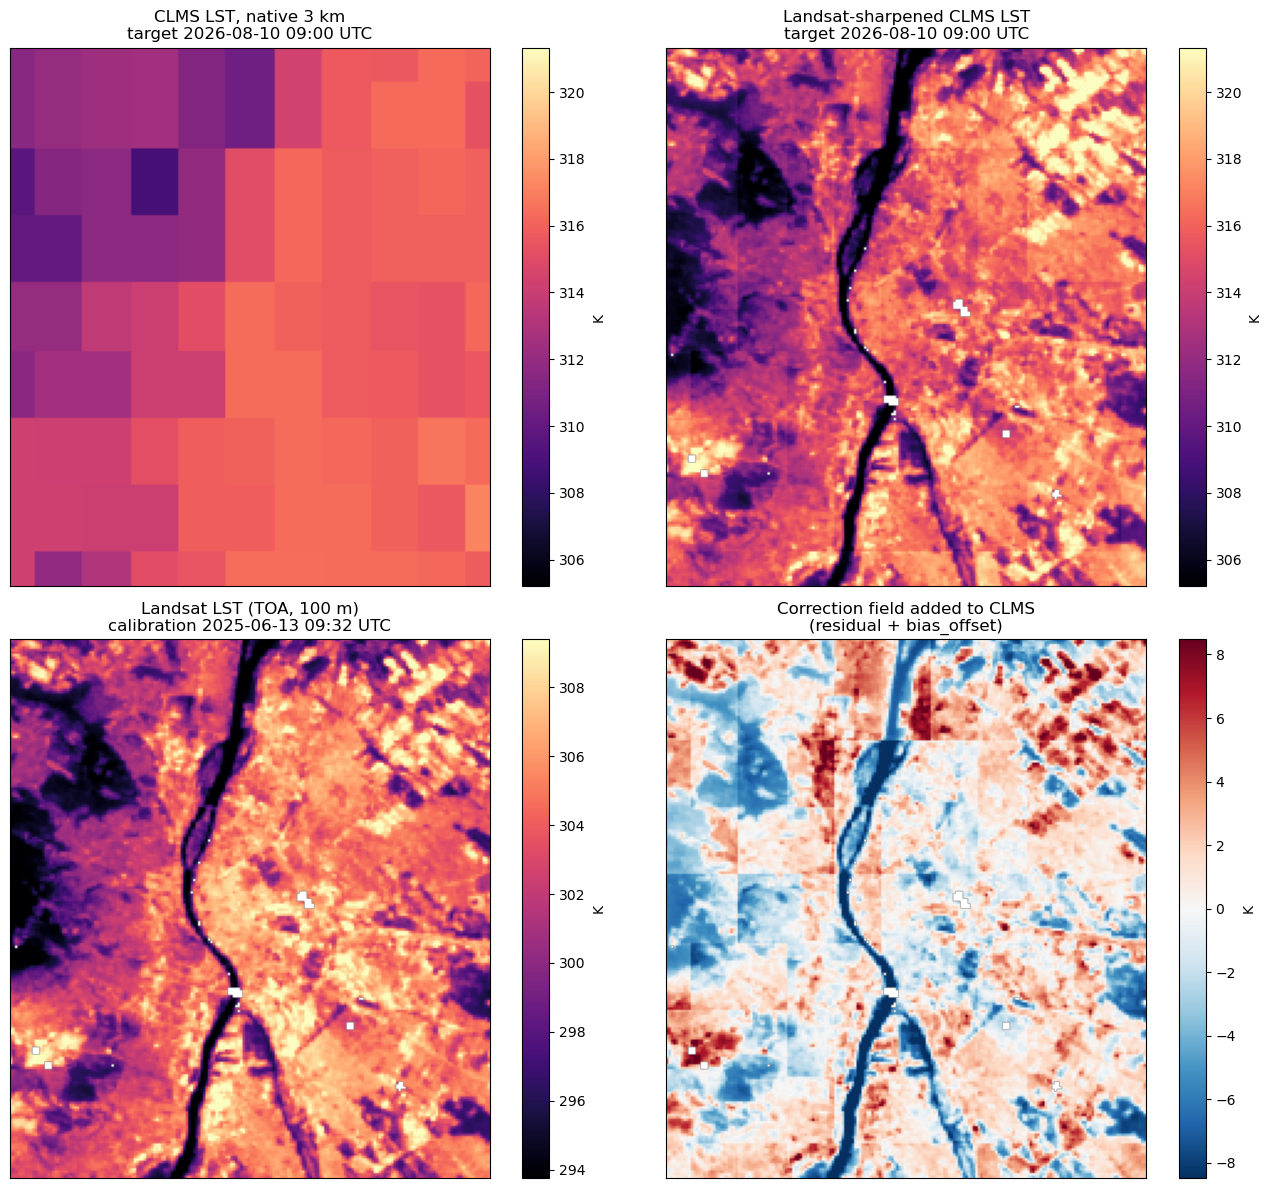

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
target = QL_TARGET_TIME[:16].replace("T", " ")
calib = QL_LANDSAT_TIME[:16].replace("T", " ")

# top row: native and sharpened target hour, on a shared colour scale
vlo, vhi = np.nanpercentile(quick["sharpened"], [2, 98])
for ax, key, title in [
    (axes[0, 0], "clms_tgt", "CLMS LST, native 3 km"),
    (axes[0, 1], "sharpened", "Landsat-sharpened CLMS LST"),
]:
    im = ax.imshow(quick[key], cmap="magma", vmin=vlo, vmax=vhi)
    ax.set_title(f"{title}\ntarget {target} UTC")
    plt.colorbar(im, ax=ax, fraction=0.046, label="K")

# bottom row: the calibration-date ingredients
lo_l, hi_l = np.nanpercentile(quick["landsat_lst"], [2, 98])
im = axes[1, 0].imshow(quick["landsat_lst"], cmap="magma", vmin=lo_l, vmax=hi_l)
axes[1, 0].set_title(f"Landsat LST (TOA, 100 m)\ncalibration {calib} UTC")
plt.colorbar(im, ax=axes[1, 0], fraction=0.046, label="K")

correction = quick["residual"] + ql_bias_offset
lim = np.nanpercentile(np.abs(correction), 98)
im = axes[1, 1].imshow(correction, cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[1, 1].set_title("Correction field added to CLMS\n(residual + bias_offset)")
plt.colorbar(im, ax=axes[1, 1], fraction=0.046, label="K")

for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

### 2.7 Reading the quick look

At 3 km the metropolitan area is only a handful of pixels, and all it shows is a broad gradient with hard cell boundaries. The sharpened map carries the structure added by the correction field: the Danube as a cool ribbon, the wooded Buda hills cooler than the dense Pest districts, and individual parks, rail yards and industrial roofs. None of that detail exists in the native CLMS field. With the default dates, all of it comes from a Landsat scene acquired more than a year before the target hour.

That is only credible if the correction field is **stable in time** - if a residual measured in June 2025 still describes August 2026. The rest of the notebook tests exactly that, and turns the test into an error estimate.

# Part 2 - Does the assumption hold in one city?

## 3. Calibration pairs over Budapest

To test whether the residual is stable, we need many residual fields over the same area: every clear-sky Landsat overpass, each paired with its CLMS slot.

### 3.1 Parameters

A multi-year window is needed. With scene cloud cover below 10 % over a fixed area, one season yields only a few scenes, while ~3 years of Landsat 8 + 9 across all months gives 10-15. The study area and resolution are those of Part 1. `BIAS_OFFSET` is left `None` and is measured from the calibration pairs in Section 5; set it to a number (K) to override.

In [11]:
# Window to search for clear-sky Landsat scenes (calibration pairs)
CALIB_TIMEFRAME = ("2022-01-01", "2024-12-31")
MAX_CLOUD = 10  # max Landsat scene cloud cover, percent
MIN_AOI_COVERAGE = 0.99  # AOI fraction a Landsat footprint must cover
MIN_VALID_FRACTION = 0.2  # AOI fraction that must survive per-pixel masking
BIAS_OFFSET = None  # K; None -> computed from the calibration pairs in Section 5

### 3.2 Finding clear-sky Landsat scenes

`find_scenes()` asks the Catalog API for Landsat acquisitions over an area within a time window, filtered by scene cloud cover. Scene cloud cover is measured over the whole ~180 km scene, so it only screens whole scenes; the `BQA` mask in the evalscript handles clouds per pixel. The function also drops **swath-edge scenes** whose footprint covers less than `min_coverage` of the area, since those would leave part of every statistic empty.

In [13]:
def find_scenes(search_bbox, timeframe, max_cloud, min_coverage, verbose=True):
    """Clear-sky Landsat scenes that (almost) fully cover the AOI, oldest first."""
    results = catalog.search(
        landsat,
        bbox=search_bbox,
        time=timeframe,
        filter=f"eo:cloud_cover < {max_cloud}",
        fields={
            "include": [
                "id",
                "properties.datetime",
                "properties.eo:cloud_cover",
                "geometry",
            ],
            "exclude": [],
        },
    )

    aoi_poly = box(*(search_bbox.lower_left + search_bbox.upper_right))
    found = []
    for r in results:
        if not r.get("geometry"):
            continue
        coverage = shape(r["geometry"]).intersection(aoi_poly).area / aoi_poly.area
        found.append(
            {
                "datetime": r["properties"]["datetime"],
                "cloud": r["properties"]["eo:cloud_cover"],
                "coverage": coverage,
            }
        )

    keep = sorted(
        (s for s in found if s["coverage"] >= min_coverage), key=lambda s: s["datetime"]
    )
    if verbose:
        print(
            f"Found {len(keep)} Landsat scenes "
            f"(cloud < {max_cloud}%, AOI coverage >= {min_coverage:.0%})"
        )
        print(f"Dropped {len(found) - len(keep)} partial-overlap (swath-edge) scenes")
        for s in keep:
            print(
                f"  {s['datetime']}  cloud={s['cloud']:.1f}%  "
                f"coverage={s['coverage']:.0%}"
            )
    return keep

### 3.3 Running the search

Aim for 10-15 scenes spread across the seasons, not only heatwaves, so that the stability test covers the range of conditions the method will be applied to. The printed list also gives exact sensing times, which can be used as `QL_LANDSAT_TIME` in Part 1.

In [14]:
scenes = find_scenes(bbox, CALIB_TIMEFRAME, MAX_CLOUD, MIN_AOI_COVERAGE)
if len(scenes) < 10:
    print("\nWARNING: fewer than 10 scenes - widen CALIB_TIMEFRAME or raise MAX_CLOUD.")

Found 42 Landsat scenes (cloud < 10%, AOI coverage >= 99%)
Dropped 32 partial-overlap (swath-edge) scenes
  2022-01-12T09:33:29.036Z  cloud=5.7%  coverage=100%
  2022-02-13T09:33:27.612Z  cloud=0.1%  coverage=100%
  2022-03-25T09:33:03.165Z  cloud=0.0%  coverage=100%
  2022-05-12T09:33:09.383Z  cloud=0.0%  coverage=100%
  2022-06-21T09:33:01.305Z  cloud=3.6%  coverage=100%
  2022-06-29T09:33:29.323Z  cloud=0.6%  coverage=100%
  2022-07-23T09:33:11.629Z  cloud=8.1%  coverage=100%
  2022-08-16T09:33:46.406Z  cloud=0.4%  coverage=100%
  2022-10-19T09:33:48.574Z  cloud=8.1%  coverage=100%
  2023-03-04T09:33:28.673Z  cloud=0.2%  coverage=100%
  2023-03-12T09:33:13.55Z  cloud=2.5%  coverage=100%
  2023-07-10T09:32:49.543Z  cloud=1.2%  coverage=100%
  2023-08-11T09:33:01.23Z  cloud=3.1%  coverage=100%
  2023-08-27T09:33:09.194Z  cloud=4.6%  coverage=100%
  2023-09-04T09:33:13.338Z  cloud=4.6%  coverage=100%
  2023-09-12T09:33:18.764Z  cloud=0.1%  coverage=100%
  2023-09-20T09:33:19.041Z  clou

### 3.4 The residual evalscript

For each pair we need the residual field and both LSTs separately (the LSTs for the scatterplots). This evalscript reuses the Landsat retrieval of Section 2.3 and has only the two calibration inputs.

In [15]:
RESIDUAL_JS = """
function setup() {
  return {
    input: [
      { datasource: "LANDSAT-OT-L1", bands: ["B03", "B04", "B05", "B10", "BQA"] },
      { datasource: "CLMS_CAL", bands: ["LST", "dataMask"] },
    ],
    output: [
      { id: "residual", bands: 1, sampleType: "FLOAT32" },
      { id: "landsat_lst", bands: 1, sampleType: "FLOAT32" },
      { id: "clms_lst", bands: 1, sampleType: "FLOAT32" },
    ],
    mosaicking: "SIMPLE",
  };
}

function evaluatePixel(samples) {
  var cl = samples.CLMS_CAL[0];
  var lstLandsat = landsatLST(samples["LANDSAT-OT-L1"][0]);
  if (!cl.dataMask || lstLandsat === null) {
    return { residual: [NaN], landsat_lst: [NaN], clms_lst: [NaN] };
  }
  var lstClms = cl.LST * CLMS_FACTOR + CLMS_OFFSET;
  return {
    residual: [lstLandsat - lstClms],
    landsat_lst: [lstLandsat],
    clms_lst: [lstClms],
  };
}
"""

residual_evalscript = "//VERSION=3\n" + LANDSAT_LST_JS + RESIDUAL_JS

`get_pair_rasters()` runs the residual evalscript for one Landsat overpass, paired with the CLMS slot that contains it (Section 2.2).

In [16]:
def get_pair_rasters(landsat_time, request_bbox, request_size):
    """Residual, Landsat LST and CLMS LST (K) for one time-matched pair."""
    out = fetch_outputs(
        residual_evalscript,
        [
            ("LANDSAT-OT-L1", landsat, landsat_window(landsat_time)),
            ("CLMS_CAL", clms, clms_window(landsat_time)),
        ],
        ["residual", "landsat_lst", "clms_lst"],
        request_bbox,
        request_size,
    )
    return out["residual"], out["landsat_lst"], out["clms_lst"]

### 3.5 Fetching all pairs

One request per pair. A pair is skipped if its valid fraction after masking falls below `MIN_VALID_FRACTION`: cloud over the area despite low scene cloud cover, or missing CLMS data. The result is a stack of residual fields, one per usable date.

In [17]:
residuals, landsat_lsts, clms_lsts, used = [], [], [], []
for s in scenes:
    try:
        res, lls, cls = get_pair_rasters(s["datetime"], bbox, size)
    except Exception as e:
        print(f"  skip {s['datetime']}: {e}")
        continue
    valid = np.isfinite(res).mean()
    if valid < MIN_VALID_FRACTION:
        print(f"  skip {s['datetime']}: mostly empty (cloud/no-data)")
        continue
    residuals.append(res)
    landsat_lsts.append(lls)
    clms_lsts.append(cls)
    used.append(s["datetime"])
    print(f"  ok   {s['datetime']}: valid pixels {valid:.0%}")

residual_stack = np.stack(residuals)
print(f"\nUsable pairs: {len(used)}")

  ok   2022-01-12T09:33:29.036Z: valid pixels 96%
  ok   2022-02-13T09:33:27.612Z: valid pixels 99%
  ok   2022-03-25T09:33:03.165Z: valid pixels 98%
  ok   2022-05-12T09:33:09.383Z: valid pixels 99%
  ok   2022-06-21T09:33:01.305Z: valid pixels 100%
  ok   2022-06-29T09:33:29.323Z: valid pixels 100%
  ok   2022-07-23T09:33:11.629Z: valid pixels 100%
  ok   2022-08-16T09:33:46.406Z: valid pixels 100%
  ok   2022-10-19T09:33:48.574Z: valid pixels 71%
  ok   2023-03-04T09:33:28.673Z: valid pixels 99%
  ok   2023-03-12T09:33:13.55Z: valid pixels 99%
  ok   2023-07-10T09:32:49.543Z: valid pixels 51%
  ok   2023-08-11T09:33:01.23Z: valid pixels 90%
  ok   2023-08-27T09:33:09.194Z: valid pixels 100%
  ok   2023-09-04T09:33:13.338Z: valid pixels 99%
  ok   2023-09-12T09:33:18.764Z: valid pixels 99%
  ok   2023-09-20T09:33:19.041Z: valid pixels 84%
  ok   2023-09-28T09:33:14.643Z: valid pixels 100%
  ok   2023-10-06T09:33:21.782Z: valid pixels 99%
  ok   2023-10-14T09:33:28.128Z: valid pixels 

## 4. Is the residual field stable in time?

If the fine-scale structure is stable, the per-pixel residual should vary little between dates. We map three things:

- **Median residual** - the correction field to reuse. Landsat L1 `B10` is top-of-atmosphere brightness temperature, so it reads several K colder than the atmospherically corrected CLMS LST. This is a large but *stable* bias, removed by `BIAS_OFFSET`. The colour scale is percentile-stretched so that the spatial structure stays visible despite the offset.
- **Temporal standard deviation** - the variability of the residual across dates. A low, spatially smooth std dev supports the sharpening assumption.
- **Valid-image count per pixel** - how many cloud-free observations went into each pixel's median and std dev. Pixels built from few images have less reliable statistics, which helps explain locally noisy std dev (e.g. over water or scene edges).

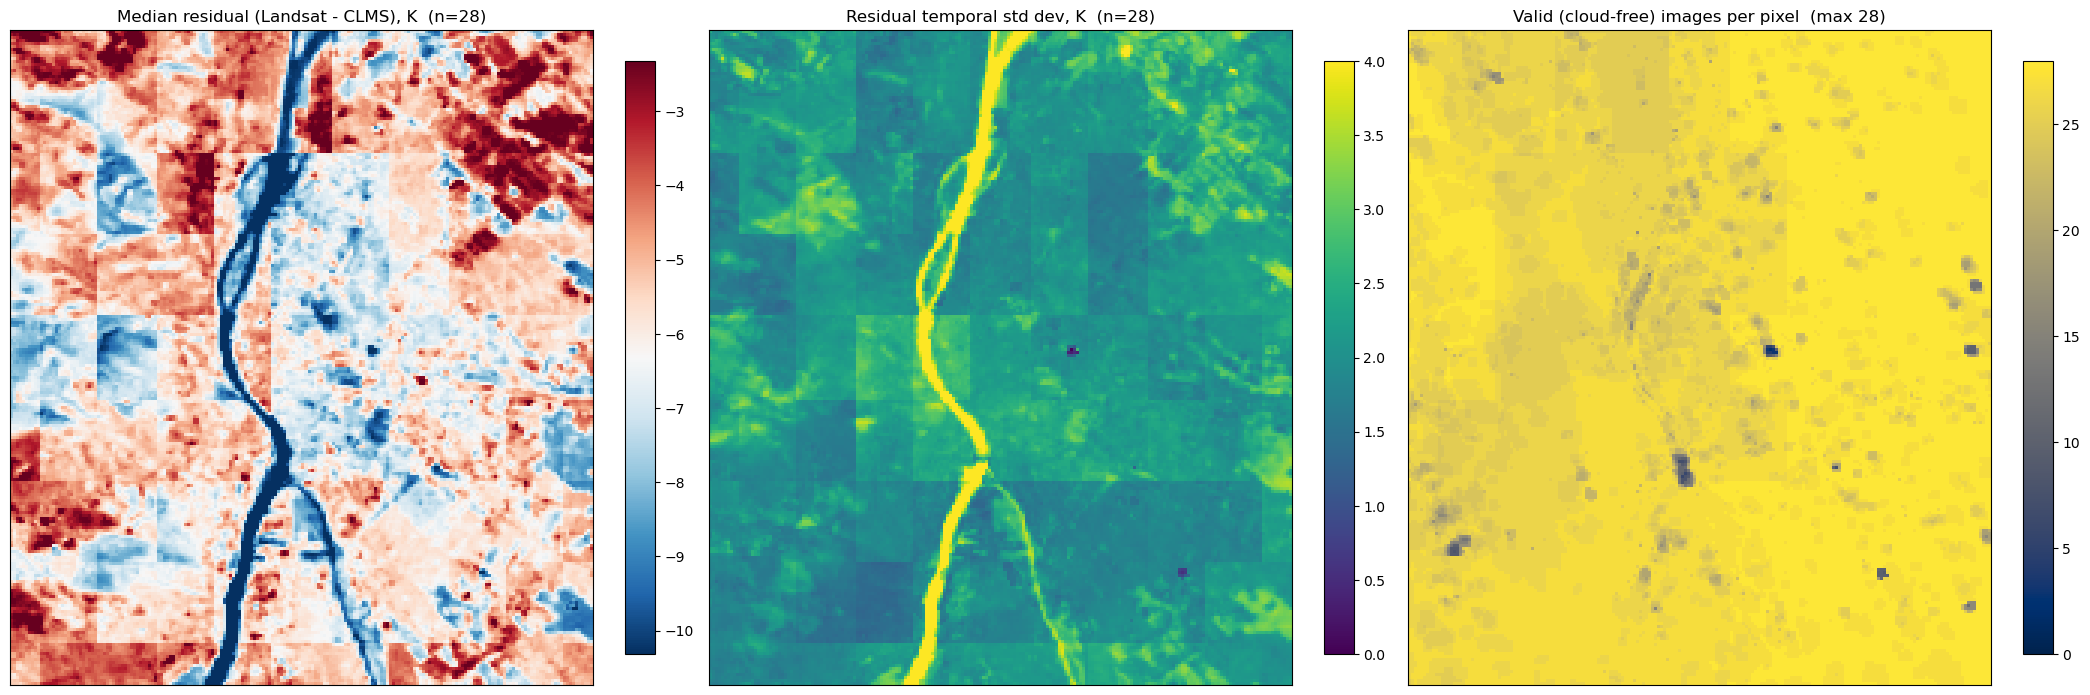

Pairs in stack: 28
Valid images per pixel: min 2, median 27, max 28
Median |residual| (spatial mean): 5.85 K
Temporal std dev  (spatial mean): 2.20 K


In [18]:
median_residual = np.nanmedian(residual_stack, axis=0)
std_residual = np.nanstd(residual_stack, axis=0)
count_valid = np.sum(np.isfinite(residual_stack), axis=0)
n_pairs = residual_stack.shape[0]

# percentile stretch so the large, stable bias does not saturate the map
vlo, vhi = np.nanpercentile(median_residual, [2, 98])

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
m = axes[0].imshow(median_residual, cmap="RdBu_r", vmin=vlo, vmax=vhi)
axes[0].set_title(f"Median residual (Landsat - CLMS), K  (n={n_pairs})")
plt.colorbar(m, ax=axes[0], fraction=0.046)
d = axes[1].imshow(std_residual, cmap="viridis", vmin=0, vmax=4)
axes[1].set_title(f"Residual temporal std dev, K  (n={n_pairs})")
plt.colorbar(d, ax=axes[1], fraction=0.046)
n = axes[2].imshow(count_valid, cmap="cividis", vmin=0, vmax=n_pairs)
axes[2].set_title(f"Valid (cloud-free) images per pixel  (max {n_pairs})")
plt.colorbar(n, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

print(f"Pairs in stack: {n_pairs}")
print(
    f"Valid images per pixel: min {int(count_valid.min())}, "
    f"median {int(np.median(count_valid))}, max {int(count_valid.max())}"
)
print(f"Median |residual| (spatial mean): {np.nanmean(np.abs(median_residual)):.2f} K")
print(f"Temporal std dev  (spatial mean): {np.nanmean(std_residual):.2f} K")

## 5. Systematic bias and the Landsat vs CLMS scatter

We pool all valid pixels across pairs and plot Landsat LST against CLMS LST. A tight cloud around a consistent offset from the 1:1 line means that the additive model holds and the offset is well defined. The mean residual is the scene-wide bias. If `BIAS_OFFSET` was not set by the user, we adopt `-mean_residual`, so that the sharpened scene mean matches CLMS.

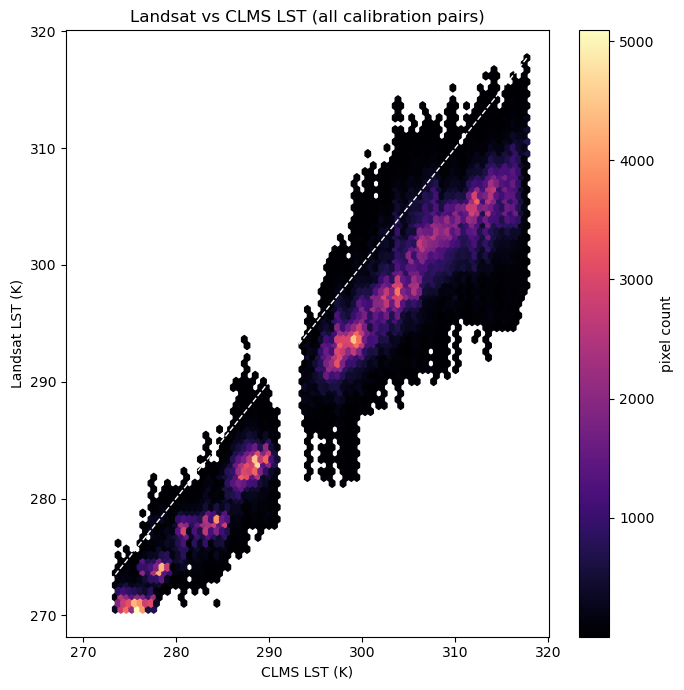

Scene-wide mean bias (Landsat - CLMS): -5.97 K
Adopted BIAS_OFFSET for sharpening:    5.97 K


In [19]:
# keep only pixels valid in both products, so the two arrays stay paired
both = [np.isfinite(a) & np.isfinite(b) for a, b in zip(landsat_lsts, clms_lsts)]
ls_all = np.concatenate([a[m] for a, m in zip(landsat_lsts, both)])
cl_all = np.concatenate([b[m] for b, m in zip(clms_lsts, both)])

mean_bias = float(np.nanmean(residual_stack))
if BIAS_OFFSET is None:
    BIAS_OFFSET = -mean_bias

lo, hi = np.percentile(np.concatenate([ls_all, cl_all]), [1, 99])
plt.figure(figsize=(7, 7))
plt.hexbin(cl_all, ls_all, gridsize=80, cmap="magma", mincnt=1, extent=(lo, hi, lo, hi))
plt.plot([lo, hi], [lo, hi], "w--", lw=1)
plt.xlabel("CLMS LST (K)")
plt.ylabel("Landsat LST (K)")
plt.title("Landsat vs CLMS LST (all calibration pairs)")
plt.colorbar(label="pixel count")
plt.tight_layout()
plt.show()

print(f"Scene-wide mean bias (Landsat - CLMS): {mean_bias:.2f} K")
print(f"Adopted BIAS_OFFSET for sharpening:    {BIAS_OFFSET:.2f} K")

## 6. Linear fit and residual structure

### 6.1 A robust least-squares helper

`linear_fit()` computes an ordinary least-squares (OLS) line in float64 on centred data, and returns the slope, intercept, R² and RMSE. We use it instead of `np.polyfit`, which silently returns a wrong slope when fitted on float32 rasters with many pixels.

In [20]:
def linear_fit(x, y):
    """OLS fit y = slope * x + intercept in float64 on centred data.

    Returns slope, intercept, R^2 and RMSE about the fit.
    """
    x = np.asarray(x, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    dx, dy = x - x.mean(), y - y.mean()
    slope = float(np.sum(dx * dy) / np.sum(dx * dx))
    intercept = float(y.mean() - slope * x.mean())
    resid = y - (slope * x + intercept)
    r2 = float(1 - np.sum(resid**2) / np.sum(dy**2))
    rmse = float(np.sqrt(np.mean(resid**2)))
    return slope, intercept, r2, rmse

### 6.2 Fit and residuals

We fit the line `Landsat = slope * CLMS + intercept` to all pooled pixels and inspect the residuals about it. A slope near 1 with small, structureless residuals means that the two products differ mainly by a constant offset, which is the additive-sharpening assumption. Curvature or a fanning residual spread would point to a scale-dependent or non-linear relationship.

**On a t-test for significance:** it is not appropriate here. A regression t-test asks whether the slope differs from zero. Firstly, nobody doubts that the two LST products are correlated, so that null hypothesis is uninteresting. Secondly, the ~10^6 pooled pixels are massively non-independent: each 3 km CLMS value is repeated across thousands of Landsat pixels, and neighbouring pixels are spatially autocorrelated. This pseudoreplication shrinks the effective sample size enormously, so a nominal t-test returns p ~ 0 for essentially any slope, regardless of model quality. We therefore report descriptive fit quality (R², RMSE), read the residual plot, and rely on the per-pixel temporal std-dev map. A meaningful significance test would first aggregate the data to independent units, e.g. one value per CLMS cell per date.

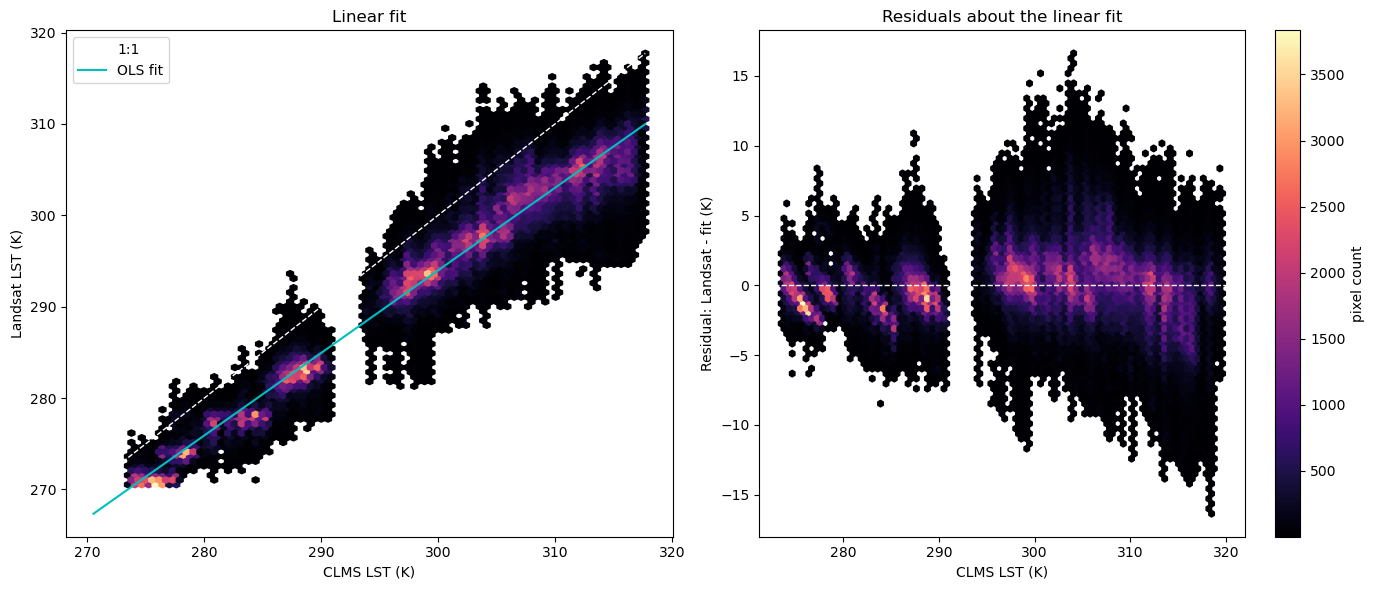

Landsat = 0.904 * CLMS + 22.93
R^2 = 0.950   RMSE about fit = 2.60 K


In [21]:
bud_slope, bud_intercept, bud_r2, bud_rmse = linear_fit(cl_all, ls_all)
fit_resid = ls_all - (bud_slope * cl_all + bud_intercept)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].hexbin(
    cl_all, ls_all, gridsize=80, cmap="magma", mincnt=1, extent=(lo, hi, lo, hi)
)
axes[0].plot([lo, hi], [lo, hi], "w--", lw=1, label="1:1")
axes[0].plot(
    [lo, hi],
    [bud_slope * lo + bud_intercept, bud_slope * hi + bud_intercept],
    "c-",
    lw=1.5,
    label="OLS fit",
)
axes[0].set_xlabel("CLMS LST (K)")
axes[0].set_ylabel("Landsat LST (K)")
axes[0].set_title("Linear fit")
axes[0].legend(loc="upper left")

axes[1].hexbin(cl_all, fit_resid, gridsize=80, cmap="magma", mincnt=1)
axes[1].axhline(0, color="w", ls="--", lw=1)
axes[1].set_xlabel("CLMS LST (K)")
axes[1].set_ylabel("Residual: Landsat - fit (K)")
axes[1].set_title("Residuals about the linear fit")
plt.colorbar(axes[1].collections[0], ax=axes[1], label="pixel count")
plt.tight_layout()
plt.show()

print(f"Landsat = {bud_slope:.3f} * CLMS + {bud_intercept:.2f}")
print(f"R^2 = {bud_r2:.3f}   RMSE about fit = {bud_rmse:.2f} K")

## 7. A single temporal-stability score

To compare the sharpening assumption across cities and climate zones, we need a scalar that measures *how constant the spatial pattern of the residual is over time*. We use two complementary numbers:

- **Pattern-stability coefficient** - the mean spatial Pearson correlation between each date's residual field and the median pattern. Pearson r removes each date's global mean and scale, so it isolates the *shape* of the pattern from the atmospheric and seasonal offset, which `BIAS_OFFSET` handles. It is dimensionless (~0-1, where 1 = perfectly stable), so it is **directly comparable between cities, regardless of their absolute temperatures**. This is the "temporal stability of spatial patterns" concept of Vachaud et al. (1985).
- **Absolute variability** - the spatial median of the per-pixel temporal std dev, in K. This is the physical "good to +/- X K" number for a single city. It is *not* scale-free, however: it mixes pattern instability with how thermally variable the climate is.

`pattern_stability_score()` computes the first number for any stack of residual fields. Part 3 reuses it for every city.

In [22]:
def pattern_stability_score(stack, reference):
    """Mean spatial Pearson r between each date's residual field and a reference."""
    corrs = []
    for layer in stack:
        m = np.isfinite(layer) & np.isfinite(reference)
        if m.sum() > 100:
            corrs.append(np.corrcoef(layer[m], reference[m])[0, 1])
    return float(np.mean(corrs)) if corrs else np.nan

We compute both numbers for Budapest. The histogram of the temporal std-dev map shows whether its median is representative, or driven by a tail such as water or edge pixels.

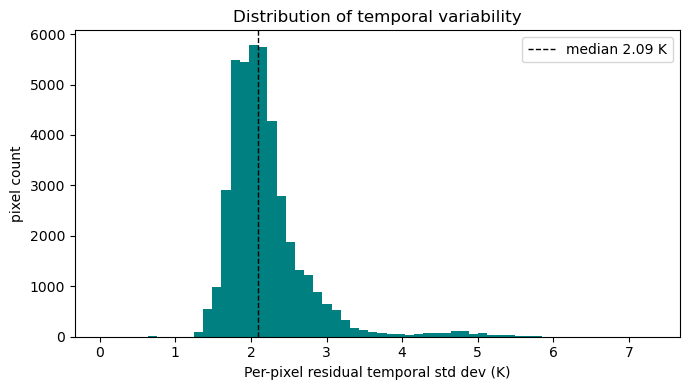

Pattern-stability coefficient (mean r to median): 0.785   [1 = perfectly stable]
Absolute variability (temporal std, K): median 2.09, mean 2.20


In [23]:
abs_stability_median = float(np.nanmedian(std_residual))
abs_stability_mean = float(np.nanmean(std_residual))
pattern_stability = pattern_stability_score(residual_stack, median_residual)

plt.figure(figsize=(7, 4))
vals = std_residual[np.isfinite(std_residual)].ravel()
plt.hist(vals, bins=60, color="teal")
plt.axvline(
    abs_stability_median,
    color="k",
    ls="--",
    lw=1,
    label=f"median {abs_stability_median:.2f} K",
)
plt.xlabel("Per-pixel residual temporal std dev (K)")
plt.ylabel("pixel count")
plt.title("Distribution of temporal variability")
plt.legend()
plt.tight_layout()
plt.show()

print(
    f"Pattern-stability coefficient (mean r to median): {pattern_stability:.3f}"
    "   [1 = perfectly stable]"
)
print(
    f"Absolute variability (temporal std, K): median {abs_stability_median:.2f}, "
    f"mean {abs_stability_mean:.2f}"
)

## 8. Interim conclusion for one city

Read the maps of Section 4, the scatter of Sections 5-6 and the scores of Section 7 together:

- A **low, spatially smooth residual std dev**, a **tight scatter around a consistent offset** and a **pattern-stability coefficient close to 1** support the assumption that the fine-scale thermal structure is stable in time. In that case sharpening is justified, and the median residual is a sound correction field.
- A **high std dev**, a **diffuse scatter** or a **low stability coefficient** would mean that simple additive sharpening is unreliable for this area.

**Result.** Over Budapest the 28 calibration pairs give a mean bias (Landsat - CLMS) of -5.97 K, so `BIAS_OFFSET` = +5.97 K. The pooled scatter of Section 5 lies below the 1:1 line everywhere, but not at a constant distance. It is about 2-3 K below the line at the cold end and about 8 K at the warm end, so the offset grows with temperature, i.e. with the season (compare Perth in Section 11.4). The scatter also splits into a cold-season and a warm-season group, with almost no dates between 290 and 293 K in CLMS. The pooled fit gives `Landsat = 0.904 * CLMS + 22.93` with R² = 0.950 and an RMSE of 2.60 K about the line (Section 6). A pooled slope of 0.90 looks close to additive, but it is dominated by the seasonal cycle; within single dates the slope is much lower (median 0.54, Section 12.4). The pattern-stability coefficient is 0.785 and the median temporal std dev of the residual 2.09 K (mean 2.20 K; Section 7). The fine-scale pattern is thus largely, but not perfectly, stable over the 28 dates, which is enough to justify sharpening and to test it further in the following parts.

Caveats: the residual also absorbs the systematic difference between the Landsat and CLMS retrieval algorithms, not only spatial structure; the additive-in-Kelvin model treats anomaly magnitude as independent of background temperature (tested in Sections 11 and 12); and only clear-sky overpass hours are observed.

One city cannot show whether the method travels, which Part 3 tests. Also, all tests so far are indirect; Part 5 validates the sharpened maps directly against Landsat.

# Part 3 - Portability across cities

## 9. Is the residual bias constant between climate zones?

Part 2 measured, for one city, how stable the spatial pattern of the Landsat-CLMS residual is, and how large its near-constant offset is. That offset, `BIAS_OFFSET`, has to be measured per city from a local Landsat/CLMS calibration pair. **If it turned out to be roughly the same everywhere, the method would become portable**: any city's CLMS LST could be sharpened without a local calibration.

This part repeats the Part 2 measurement over **ten cities spanning the Köppen-Geiger classes**, over the **same 2022-2025 window** for each, so that no city gains an advantage from a longer record. For each city we compute the same quantities as Sections 4-7: the median residual map, the temporal std-dev map, the pooled Landsat-vs-CLMS scatter with an OLS fit, and the two summary scores.

**Two things are being tested, and they are independent:**

| Question | Metric | What a good result looks like |
| --- | --- | --- |
| Is the *bias* portable? | mean residual per city, K | all cities within a few K of each other |
| Is *sharpening* valid at all here? | pattern-stability coefficient | close to 1 in every city |

**Why four years and not one.** Budapest needed a three-year window to reach 10-15 clear-sky scenes, and Budapest is not a cloudy city by world standards. A single year would leave Seoul, Chennai, Nairobi and Brasilia with a handful of usable dates each. That is too few for a temporal statistic, and unequal enough between cities to make the comparison meaningless. Two further settings help. The per-scene cloud threshold is relaxed, because per-pixel `BQA` masking does the real work and scene-level cloud over a 180 km Landsat scene says little about a 22 km area. And Landsat 8 + 9 together give an effective 8-day revisit.

**The window is capped, not exhausted.** Four years yields far more candidates than needed, and each scene costs one Process API request. Each city therefore takes an evenly spaced subset of at most `CITY_MAX_SCENES` acquisitions across the window. This bounds the runtime, keeps the seasonal spread balanced, and makes `n` comparable between cities instead of rewarding the cloud-free ones with a much larger sample. Cities that still fall below `CITY_MIN_PAIRS` are reported and excluded rather than silently averaged in.

**CLMS coverage is not globally uniform.** The CLMS LST product is built from geostationary sensors, so its coverage and quality depend on viewing geometry: high latitudes, and longitudes far from a sub-satellite point, are seen obliquely or not at all. Novosibirsk is the most exposed city in this list. Each city is probed for CLMS data before any expensive request is made, and cities with no coverage are skipped with a message rather than failing mid-loop.

**Runtime.** Ten cities at up to `CITY_MAX_SCENES` scenes each is on the order of 200 Process API requests, so expect this part to take a while. Results accumulate in `city_results` and the loop skips cities already done, so an interrupted run resumes by re-running the loop cell alone.

### 9.1 Cities

The ten cities with their approximate centre and Köppen-Geiger climate class (Beck et al., 2018).

In [24]:
# name, lat, lon, Koeppen-Geiger zone
CITIES = [
    ("Novosibirsk", 55.03, 82.92, "Dfb"),  # humid continental, cold winter
    ("London", 51.51, -0.13, "Cfb"),  # temperate oceanic
    ("Chicago", 41.88, -87.63, "Dfa"),  # humid continental, hot summer
    ("Istanbul", 41.01, 28.98, "Csa"),  # Mediterranean
    ("Seoul", 37.57, 126.98, "Dwa"),  # continental monsoon
    ("Alicante", 38.35, -0.48, "BSh"),  # hot semi-arid
    ("Perth", -31.95, 115.86, "Csa"),  # Mediterranean, southern hemisphere
    ("Brasilia", -15.79, -47.88, "Aw"),  # tropical savanna, highland
    ("Chennai", 13.08, 80.27, "Aw"),  # tropical wet and dry, coastal
    ("Nairobi", -1.29, 36.82, "Cwb"),  # subtropical highland
]

for name, lat, lon, zone in CITIES:
    print(f"{name:<14} {zone:<5} lat {lat:>7.2f}  lon {lon:>8.2f}")

Novosibirsk    Dfb   lat   55.03  lon    82.92
London         Cfb   lat   51.51  lon    -0.13
Chicago        Dfa   lat   41.88  lon   -87.63
Istanbul       Csa   lat   41.01  lon    28.98
Seoul          Dwa   lat   37.57  lon   126.98
Alicante       BSh   lat   38.35  lon    -0.48
Perth          Csa   lat  -31.95  lon   115.86
Brasilia       Aw    lat  -15.79  lon   -47.88
Chennai        Aw    lat   13.08  lon    80.27
Nairobi        Cwb   lat   -1.29  lon    36.82


### 9.2 Parameters

- `CITY_TIMEFRAME` - one common four-year window for every city.
- `CITY_HALF_LAT`, `CITY_RESOLUTION` - a ~22 km box at 100 m. The longitude extent is widened by 1/cos(latitude), so that boxes are roughly square on the ground.
- `CITY_MAX_CLOUD`, `CITY_MIN_VALID_FRACTION` - a relaxed scene cloud filter, backed by the per-pixel `BQA` mask and a minimum valid fraction per pair.
- `CITY_MAX_SCENES`, `CITY_MIN_PAIRS` - the cap on requests per city, and the minimum number of usable pairs for a city to be reported.
- `CITY_SCATTER_SAMPLE` - the number of pixels per city kept for the scatterplot and regression.
- `CLMS_PROBE_WINDOW` - a short window used to check that CLMS covers a city at all.

Re-running this cell resets `city_results`.

In [25]:
# Same window for every city, so none gets an advantage from a longer record
CITY_TIMEFRAME = ("2022-01-01", "2025-12-31")

CITY_HALF_LAT = 0.10  # half-height in degrees -> ~22 km box side
CITY_RESOLUTION = 100  # m
CITY_MIN_COVERAGE = 0.95  # AOI fraction a Landsat footprint must cover

# Scene cloud cover describes the whole ~180 km scene, not a 22 km AOI: let more
# scenes through and rely on the per-pixel BQA mask, then drop mostly empty results
CITY_MAX_CLOUD = 40  # percent, per scene
CITY_MIN_VALID_FRACTION = 0.3  # fraction of AOI pixels that must survive masking

CITY_MAX_SCENES = 20  # evenly spaced candidates requested per city
CITY_MIN_PAIRS = 8  # below this a city is reported but excluded

CITY_SCATTER_SAMPLE = 150_000  # pixels kept per city for the scatter and fit
CLMS_PROBE_WINDOW = ("2025-07-01", "2025-07-03")  # CLMS coverage probe
STD_VMAX = 4  # K, shared colour scale for the std-dev maps

city_results = {}  # rerun the loop cell alone to resume; rerun this cell to reset

print(
    f"{len(CITIES)} cities, {CITY_TIMEFRAME[0][:4]}-{CITY_TIMEFRAME[1][:4]}, "
    f"~{2 * CITY_HALF_LAT * 111:.0f} km boxes at {CITY_RESOLUTION} m, "
    f"up to {CITY_MAX_SCENES} scenes each"
)

10 cities, 2022-2025, ~22 km boxes at 100 m, up to 20 scenes each


### 9.3 Helper functions

- `city_bbox()` builds a roughly square box around a city centre.
- `clms_available()` is a cheap Catalog probe for CLMS coverage.
- `spread_evenly()` picks at most *k* evenly spaced scenes from the date-sorted search result.

In [26]:
def city_bbox(lat, lon, half_lat=CITY_HALF_LAT):
    """Roughly square ground box centred on the city (longitude widened by 1/cos)."""
    half_lon = half_lat / np.cos(np.deg2rad(lat))
    return BBox(
        [lon - half_lon, lat - half_lat, lon + half_lon, lat + half_lat], crs=CRS.WGS84
    )


def clms_available(bb):
    """Cheap probe: does the CLMS BYOC collection hold anything over this box?"""
    try:
        hits = catalog.search(
            clms,
            bbox=bb,
            time=CLMS_PROBE_WINDOW,
            fields={"include": ["id"], "exclude": []},
        )
        return len(list(hits)) > 0
    except Exception:
        return True  # probe failed - let the fusion request be the judge


def spread_evenly(items, k):
    """At most k items, evenly spaced through the (date-sorted) list."""
    if len(items) <= k:
        return items
    idx = np.linspace(0, len(items) - 1, k).round().astype(int)
    return [items[i] for i in idx]

### 9.4 Fetching one city's calibration pairs

`fetch_city_pairs()` is the city version of the loop in Section 3.5. For every usable date it keeps the residual field, the valid Landsat and CLMS pixel values, their month (for the seasonal diagnostic in Section 11.4), the scene-mean CLMS temperature (for the validation in Part 5) and the spatial slope within that single date (Section 11.1).

In [27]:
def fetch_city_pairs(scenes, bb, sz, min_valid_fraction):
    """Fetch every calibration pair for one city and keep the usable ones."""
    pairs = {
        "residuals": [],
        "ls": [],
        "cl": [],
        "month": [],
        "dates": [],
        "clms_mean": [],
        "slope": [],
    }
    for s in scenes:
        try:
            res, lls, cls_ = get_pair_rasters(s["datetime"], bb, sz)
        except Exception:
            continue
        if np.isfinite(res).mean() < min_valid_fraction:
            continue
        m = np.isfinite(lls) & np.isfinite(cls_)
        pairs["residuals"].append(res)
        pairs["ls"].append(lls[m])
        pairs["cl"].append(cls_[m])
        pairs["month"].append(np.full(int(m.sum()), int(s["datetime"][5:7])))
        pairs["dates"].append(s["datetime"][:10])
        pairs["clms_mean"].append(float(np.mean(cls_[m])))
        # spatial slope within this single date (Section 11.1)
        if m.sum() > 1000 and np.ptp(cls_[m]) > 0:
            pairs["slope"].append(linear_fit(cls_[m], lls[m])[0])
        else:
            pairs["slope"].append(np.nan)
    return pairs

### 9.5 Per-city statistics

`summarise_city()` reduces the fetched pairs to the Part 2 statistics: median and std-dev maps, mean bias, the between-date spread of the scene-mean bias, the pattern-stability coefficient, and the pooled regression on a random subsample of `CITY_SCATTER_SAMPLE` pixels. It also keeps the residual stack for the validation in Part 5.

In [28]:
def summarise_city(out, pairs, min_pairs):
    """Add the Part 2 statistics for one city to the result dict `out`."""
    out["n_pairs"], out["dates"] = len(pairs["residuals"]), pairs["dates"]
    out["slope_per_date"], out["clms_means"] = pairs["slope"], pairs["clms_mean"]
    if out["n_pairs"] < min_pairs:
        out["status"] = f"only {out['n_pairs']} usable pairs (need {min_pairs})"
        return out

    arr = np.stack(pairs["residuals"])
    out["residual_stack"] = arr
    out["median_residual"] = np.nanmedian(arr, axis=0)
    out["std_residual"] = np.nanstd(arr, axis=0)
    out["std_median"] = float(np.nanmedian(out["std_residual"]))
    out["mean_bias"] = float(np.nanmean(arr))
    out["bias_sd_between_dates"] = float(np.std([np.nanmean(a) for a in arr]))
    out["pattern_stability"] = pattern_stability_score(arr, out["median_residual"])

    ls_pool = np.concatenate(pairs["ls"])
    cl_pool = np.concatenate(pairs["cl"])
    mon_pool = np.concatenate(pairs["month"])
    if ls_pool.size > CITY_SCATTER_SAMPLE:
        idx = np.random.default_rng(0).choice(
            ls_pool.size, CITY_SCATTER_SAMPLE, replace=False
        )
        ls_pool, cl_pool, mon_pool = ls_pool[idx], cl_pool[idx], mon_pool[idx]
    out["slope"], out["intercept"], out["r2"], out["rmse"] = linear_fit(
        cl_pool, ls_pool
    )
    out["ls_pool"], out["cl_pool"], out["mon_pool"] = ls_pool, cl_pool, mon_pool
    out["clms_spatial_sd"] = float(np.std(cl_pool))
    out["status"] = "ok"
    return out

`analyse_city()` ties the steps together for one city: build the box, probe CLMS coverage, search for scenes, thin them out, fetch the pairs and summarise. The box geometry and thresholds are arguments, so the same function serves both the reported 22 km / 100 m run and the wider diagnostic runs of Section 11.2.

In [29]:
def analyse_city(
    name,
    lat,
    lon,
    half_lat=CITY_HALF_LAT,
    resolution=CITY_RESOLUTION,
    max_scenes=CITY_MAX_SCENES,
    min_pairs=CITY_MIN_PAIRS,
    min_coverage=CITY_MIN_COVERAGE,
    min_valid_fraction=CITY_MIN_VALID_FRACTION,
):
    """All Part 2 statistics for one city."""
    bb = city_bbox(lat, lon, half_lat)
    sz = bbox_to_dimensions(bb, resolution=resolution)
    out = {
        "name": name,
        "bbox": bb,
        "size": sz,
        "half_lat": half_lat,
        "resolution": resolution,
        "n_scenes_found": 0,
        "n_requested": 0,
        "n_pairs": 0,
        "status": "",
    }
    if not clms_available(bb):
        out["status"] = "no CLMS LST coverage"
        return out

    scenes = find_scenes(
        bb, CITY_TIMEFRAME, CITY_MAX_CLOUD, min_coverage, verbose=False
    )
    out["n_scenes_found"] = len(scenes)
    scenes = spread_evenly(scenes, max_scenes)
    out["n_requested"] = len(scenes)
    pairs = fetch_city_pairs(scenes, bb, sz, min_valid_fraction)
    return summarise_city(out, pairs, min_pairs)

### 9.6 Running all cities

This is the expensive cell (~200 requests). It is resumable: cities already analysed successfully are skipped. `ok` collects the successful cities for all following sections.

In [30]:
for name, lat, lon, zone in CITIES:
    if city_results.get(name, {}).get("status") == "ok":
        print(f"{name:<14} cached ({city_results[name]['n_pairs']} pairs)")
        continue
    print(f"{name:<14} ...", end=" ", flush=True)
    r = analyse_city(name, lat, lon)
    r.update({"zone": zone, "lat": lat, "lon": lon})
    city_results[name] = r
    if r["status"] == "ok":
        print(
            f"ok: {r['n_pairs']} usable of {r['n_requested']} requested "
            f"({r['n_scenes_found']} clear-sky scenes in window), "
            f"bias {r['mean_bias']:+.2f} K, stability {r['pattern_stability']:.3f}"
        )
    else:
        print(r["status"])

ok = [city_results[c[0]] for c in CITIES if city_results[c[0]]["status"] == "ok"]
print(f"\n{len(ok)}/{len(CITIES)} cities analysed successfully")
for c in CITIES:
    if city_results[c[0]]["status"] != "ok":
        print(f"  excluded: {c[0]:<14} {city_results[c[0]]['status']}")
if not ok:
    raise RuntimeError("No city produced enough usable pairs - see the output above.")

Novosibirsk    ... only 2 usable pairs (need 8)
London         ... only 6 usable pairs (need 8)
Chicago        ... ok: 13 usable of 20 requested (149 clear-sky scenes in window), bias -3.69 K, stability 0.847
Istanbul       ... 

/tmp/ipykernel_9979/2270804353.py:11: RuntimeWarning: All-NaN slice encountered
  out["median_residual"] = np.nanmedian(arr, axis=0)
/opt/conda/envs/sentinelhub/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


ok: 11 usable of 20 requested (197 clear-sky scenes in window), bias -3.98 K, stability 0.792
Seoul          ... 

/tmp/ipykernel_9979/2270804353.py:11: RuntimeWarning: All-NaN slice encountered
  out["median_residual"] = np.nanmedian(arr, axis=0)
/opt/conda/envs/sentinelhub/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


ok: 17 usable of 20 requested (91 clear-sky scenes in window), bias -6.30 K, stability 0.790
Alicante       ... 

...

ok: 12 usable of 20 requested (422 clear-sky scenes in window), bias -2.77 K, stability 0.719
Perth          ... ok: 14 usable of 20 requested (247 clear-sky scenes in window), bias -6.76 K, stability 0.794
Brasilia       ... 

/tmp/ipykernel_9979/2270804353.py:11: RuntimeWarning: All-NaN slice encountered
  out["median_residual"] = np.nanmedian(arr, axis=0)
/opt/conda/envs/sentinelhub/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


ok: 13 usable of 20 requested (167 clear-sky scenes in window), bias -3.74 K, stability 0.808
Chennai        ... ok: 10 usable of 20 requested (92 clear-sky scenes in window), bias -2.47 K, stability 0.826
Nairobi        ... 

/tmp/ipykernel_9979/2270804353.py:11: RuntimeWarning: All-NaN slice encountered
  out["median_residual"] = np.nanmedian(arr, axis=0)
/opt/conda/envs/sentinelhub/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


ok: 8 usable of 20 requested (88 clear-sky scenes in window), bias -1.89 K, stability 0.832

8/10 cities analysed successfully
  excluded: Novosibirsk    only 2 usable pairs (need 8)
  excluded: London         only 6 usable pairs (need 8)


## 10. Results across cities

### 10.1 Median residual maps

The median residual (the correction field) for every city. Each panel is percentile-stretched *individually*, because the bias level differs more between cities than the spatial structure within any one of them; a shared scale would flatten every map to a single colour. Read these maps for *pattern*, not level. The level is shown in the summary figure of Section 10.4.

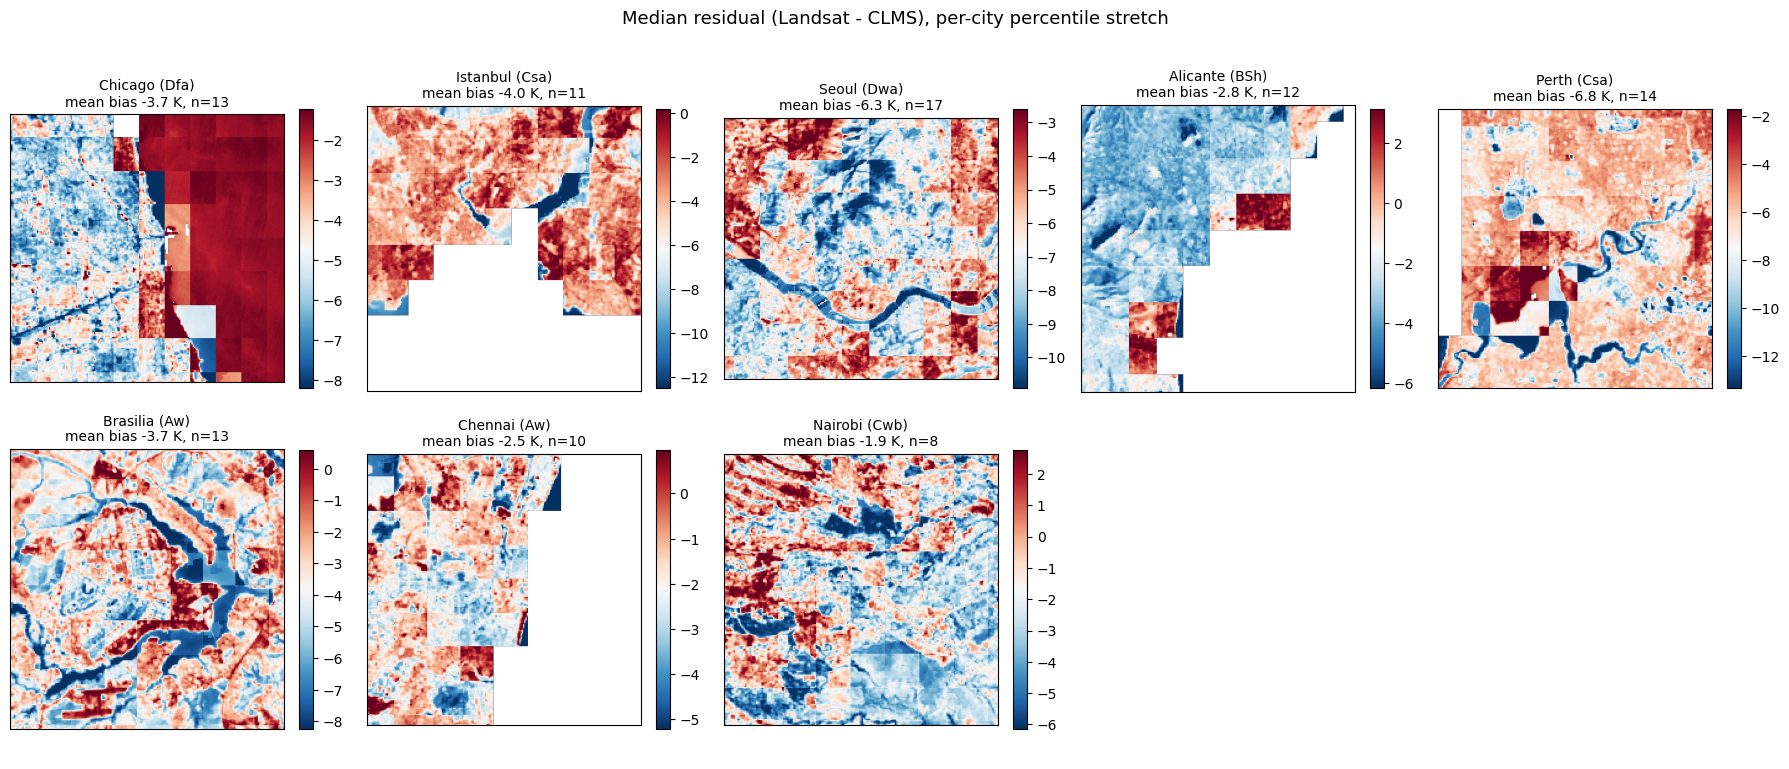

In [31]:
ncol = 5
nrow = int(np.ceil(len(ok) / ncol))

fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.9 * nrow), squeeze=False)
for ax, r in zip(axes.ravel(), ok):
    vlo, vhi = np.nanpercentile(r["median_residual"], [2, 98])
    im = ax.imshow(r["median_residual"], cmap="RdBu_r", vmin=vlo, vmax=vhi)
    ax.set_title(
        f"{r['name']} ({r['zone']})\n"
        f"mean bias {r['mean_bias']:+.1f} K, n={r['n_pairs']}",
        fontsize=10,
    )
    ax.set_xticks([])
    ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046)
for ax in axes.ravel()[len(ok) :]:
    ax.axis("off")
fig.suptitle(
    "Median residual (Landsat - CLMS), per-city percentile stretch", fontsize=13
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 10.2 Temporal std-dev maps

The same grid for the temporal std dev of the residual, this time on a **shared** 0 to `STD_VMAX` K scale so that cities are directly comparable. This is the map that shows where, and how badly, the sharpening assumption fails.

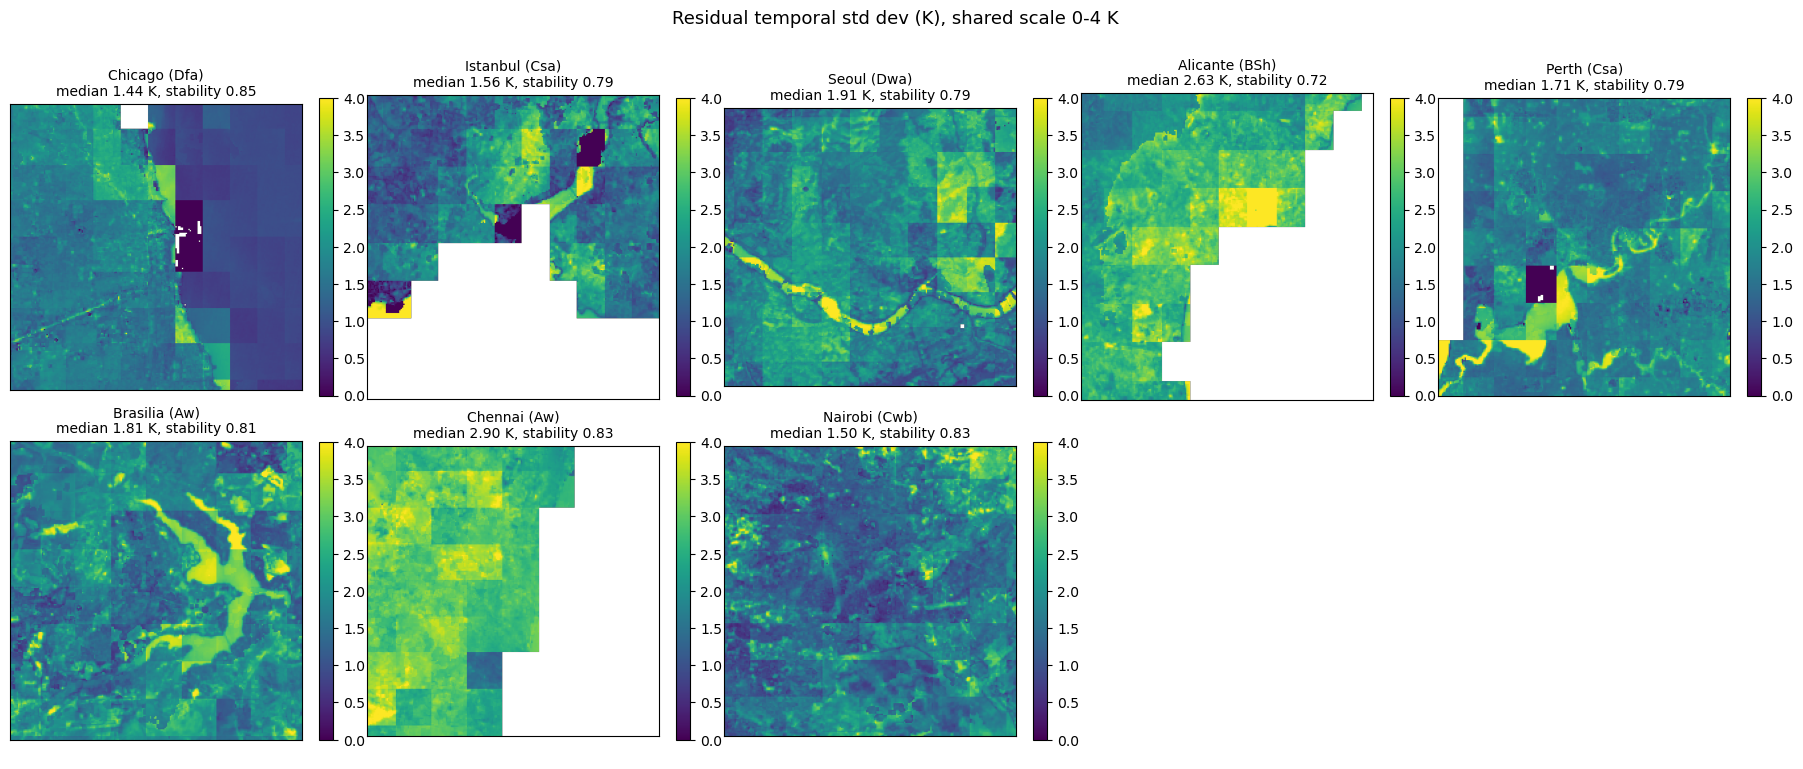

In [32]:
fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.9 * nrow), squeeze=False)
for ax, r in zip(axes.ravel(), ok):
    im = ax.imshow(r["std_residual"], cmap="viridis", vmin=0, vmax=STD_VMAX)
    ax.set_title(
        f"{r['name']} ({r['zone']})\nmedian {r['std_median']:.2f} K, "
        f"stability {r['pattern_stability']:.2f}",
        fontsize=10,
    )
    ax.set_xticks([])
    ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046)
for ax in axes.ravel()[len(ok) :]:
    ax.axis("off")
fig.suptitle(f"Residual temporal std dev (K), shared scale 0-{STD_VMAX} K", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 10.3 Landsat vs CLMS scatter per city

One hexbin scatterplot panel per city, pooling all valid pixels from all of that city's pairs (subsampled to `CITY_SCATTER_SAMPLE` points). The white dashed line is 1:1 and the cyan line is the OLS fit; the vertical distance between them is the bias.

What to look for: a **tight cloud parallel to 1:1** means a clean additive offset. A slope well below 1 means that CLMS compresses the dynamic range relative to Landsat, which is expected to some degree because a 3 km pixel averages hot and cool surfaces together. A **fanning or curved** cloud means that the offset depends on temperature, which would break the purely additive model. Part 4 examines the slope in detail.

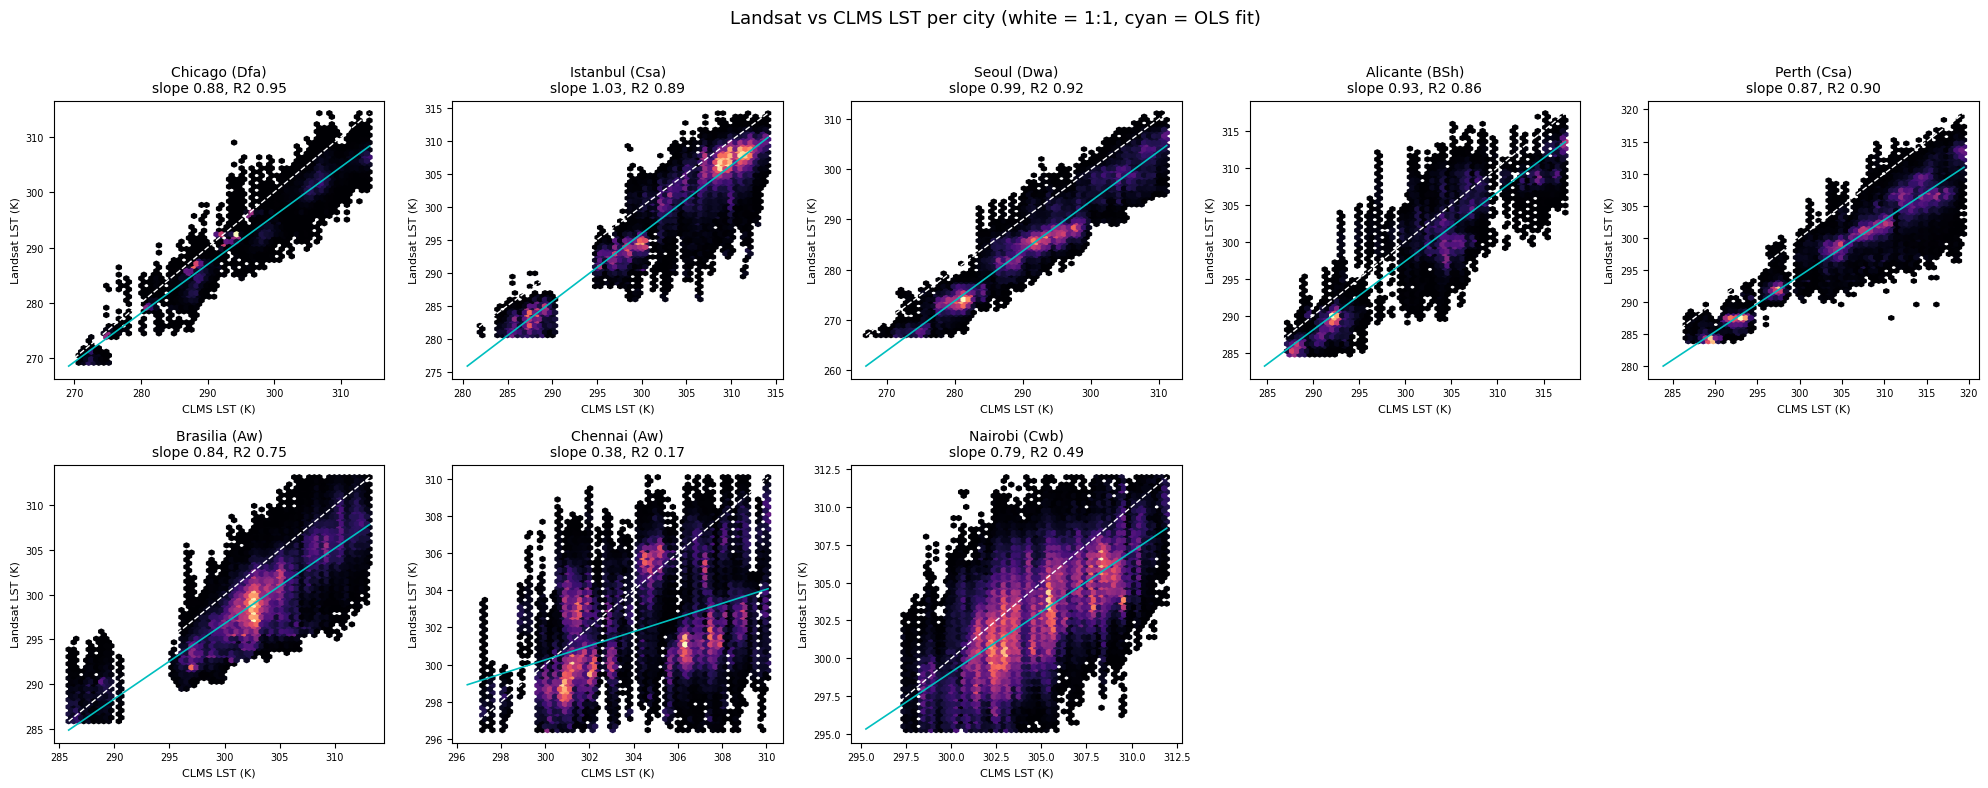

In [33]:
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 4 * nrow), squeeze=False)
for ax, r in zip(axes.ravel(), ok):
    lo_c, hi_c = np.percentile(np.concatenate([r["ls_pool"], r["cl_pool"]]), [1, 99])
    ax.hexbin(
        r["cl_pool"],
        r["ls_pool"],
        gridsize=60,
        cmap="magma",
        mincnt=1,
        extent=(lo_c, hi_c, lo_c, hi_c),
    )
    ax.plot([lo_c, hi_c], [lo_c, hi_c], "w--", lw=1)
    ax.plot(
        [lo_c, hi_c],
        [r["slope"] * lo_c + r["intercept"], r["slope"] * hi_c + r["intercept"]],
        "c-",
        lw=1.2,
    )
    ax.set_title(
        f"{r['name']} ({r['zone']})\nslope {r['slope']:.2f}, R2 {r['r2']:.2f}",
        fontsize=10,
    )
    ax.set_xlabel("CLMS LST (K)", fontsize=8)
    ax.set_ylabel("Landsat LST (K)", fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(ok) :]:
    ax.axis("off")
fig.suptitle("Landsat vs CLMS LST per city (white = 1:1, cyan = OLS fit)", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 10.4 Cross-city comparison

This figure answers the research question of this part. It has three panels, with cities sorted by bias and coloured by climate zone:

1. **Mean bias per city**, with error bars showing the *between-date* std dev of the scene-mean residual within that city. The comparison that matters is between-city spread versus within-city spread: if the bars sit at a similar value and the error bars overlap, a single global `BIAS_OFFSET` is defensible.
2. **Pattern-stability coefficient** - the scale-free measure of whether sharpening is valid at all in that city.
3. **Median temporal std dev** (K) - the physical "good to +/- X K" number.

First, sort the cities and assign one colour per climate zone:

In [34]:
order = sorted(ok, key=lambda r: r["mean_bias"])
zones = sorted({r["zone"] for r in order})
zone_color = dict(zip(zones, plt.cm.tab10(np.linspace(0, 1, len(zones)))))
colors = [zone_color[r["zone"]] for r in order]
biases = np.array([r["mean_bias"] for r in order])
y = np.arange(len(order))

Then draw the three panels:

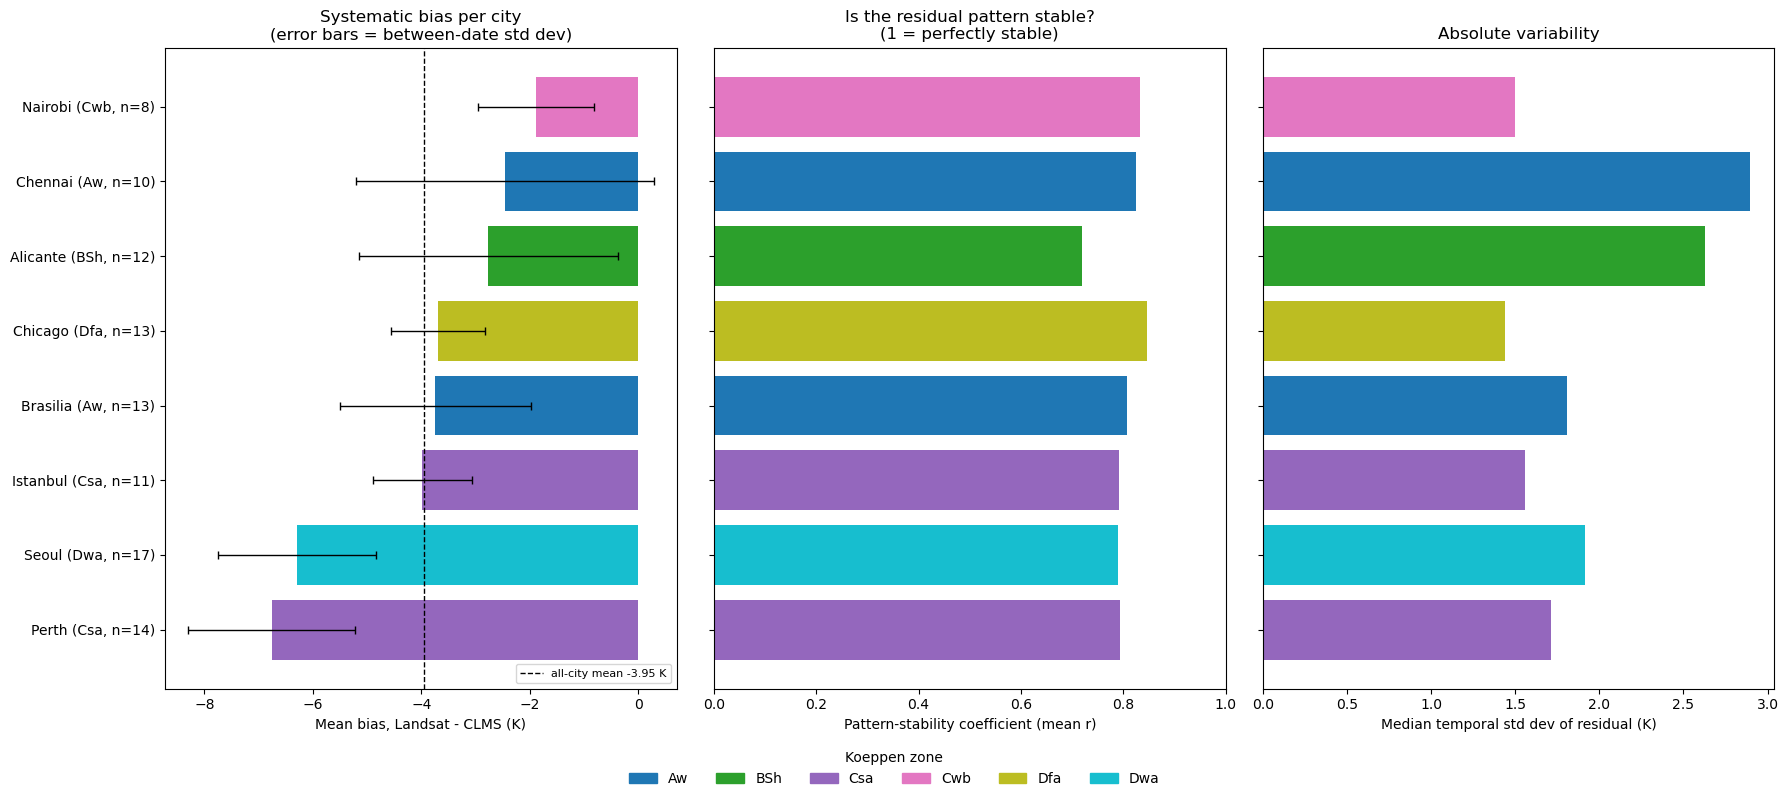

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 0.5 * len(order) + 4), sharey=True)

axes[0].barh(y, biases, color=colors)
axes[0].errorbar(
    biases,
    y,
    xerr=[r["bias_sd_between_dates"] for r in order],
    fmt="none",
    ecolor="k",
    capsize=3,
    lw=1,
)
axes[0].axvline(
    biases.mean(),
    color="k",
    ls="--",
    lw=1,
    label=f"all-city mean {biases.mean():+.2f} K",
)
axes[0].set_xlabel("Mean bias, Landsat - CLMS (K)")
axes[0].set_title("Systematic bias per city\n(error bars = between-date std dev)")
axes[0].legend(loc="lower right", fontsize=8)

axes[1].barh(y, [r["pattern_stability"] for r in order], color=colors)
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Pattern-stability coefficient (mean r)")
axes[1].set_title("Is the residual pattern stable?\n(1 = perfectly stable)")

axes[2].barh(y, [r["std_median"] for r in order], color=colors)
axes[2].set_xlabel("Median temporal std dev of residual (K)")
axes[2].set_title("Absolute variability")

axes[0].set_yticks(y)
axes[0].set_yticklabels([f"{r['name']} ({r['zone']}, n={r['n_pairs']})" for r in order])
handles = [plt.Rectangle((0, 0), 1, 1, color=zone_color[z]) for z in zones]
fig.legend(
    handles,
    zones,
    title="Koeppen zone",
    loc="lower center",
    ncol=len(zones),
    frameon=False,
)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

### 10.5 Summary table

The same numbers as a table, together with the pooled OLS slope and R². The last line gives the ratio of between-city to within-city bias spread as a single summary statistic.

In [36]:
within = np.mean([r["bias_sd_between_dates"] for r in order])
print(
    f"{'City':<14}{'Zone':<6}{'n':>4}{'bias K':>10}{'sd K':>8}"
    f"{'stab':>8}{'stdK':>8}{'slope':>8}{'R2':>7}"
)
print("-" * 73)
for r in order:
    print(
        f"{r['name']:<14}{r['zone']:<6}{r['n_pairs']:>4}{r['mean_bias']:>10.2f}"
        f"{r['bias_sd_between_dates']:>8.2f}{r['pattern_stability']:>8.3f}"
        f"{r['std_median']:>8.2f}{r['slope']:>8.3f}{r['r2']:>7.3f}"
    )
print("-" * 73)
print(
    f"Between-city spread of the bias: {biases.std():.2f} K "
    f"(range {biases.min():+.2f} to {biases.max():+.2f} K)"
)
print(f"Mean within-city between-date spread: {within:.2f} K")
print(
    f"Ratio between-city / within-city: {biases.std() / within:.2f}   "
    f"(~1 => bias behaves like a global constant; >>1 => city-dependent)"
)

City          Zone     n    bias K    sd K    stab    stdK   slope     R2
-------------------------------------------------------------------------
Perth         Csa     14     -6.76    1.53   0.794    1.71   0.871  0.899
Seoul         Dwa     17     -6.30    1.46   0.790    1.91   0.993  0.925
Istanbul      Csa     11     -3.98    0.91   0.792    1.56   1.029  0.895
Brasilia      Aw      13     -3.74    1.76   0.808    1.81   0.842  0.753
Chicago       Dfa     13     -3.69    0.87   0.847    1.44   0.881  0.947
Alicante      BSh     12     -2.77    2.39   0.719    2.63   0.929  0.863
Chennai       Aw      10     -2.47    2.75   0.826    2.90   0.380  0.170
Nairobi       Cwb      8     -1.89    1.07   0.832    1.50   0.794  0.486
-------------------------------------------------------------------------
Between-city spread of the bias: 1.63 K (range -6.76 to -1.89 K)
Mean within-city between-date spread: 1.59 K
Ratio between-city / within-city: 1.03   (~1 => bias behaves like a global c

### 10.6 Does the method travel?

**Result.** Eight cities passed the thresholds (London and Novosibirsk did not). The bias ranges from -6.76 K (Perth) to -1.89 K (Nairobi). Its spread between cities (1.63 K) is the same as its spread between dates within a city (1.59 K on average), a ratio of 1.03. At this level the bias behaves like a global constant: knowing the city does not predict it better than knowing the date. The pattern-stability coefficient is between 0.72 (Alicante) and 0.85 (Chicago) in every city, with a median temporal std dev of the residual of 1.4-2.9 K. Alicante and Chennai have the least stable patterns and the largest between-date spread of the bias.

The water-vapour prediction below is **not** supported. The dry subtropical Perth has the largest bias and the humid tropical Chennai and Nairobi the smallest. Nairobi's small bias fits its altitude (about 1700 m, hence a thinner air column), but Chennai's does not fit at all. Other factors, discussed under the caveats below, evidently matter as much as the water vapour column.

**On the bias.** Compare the *spread of the bias between cities* (the range in the left panel of Section 10.4) with the *between-date spread within each city* (the error bars). If the two are of similar size, the bias behaves like a single global constant, and `BIAS_OFFSET` could be hard-coded, making the method portable to any city without a local calibration. If the between-city spread is much larger, the bias is not a constant. The printed ratio summarises exactly this.

Physically, we expect the second outcome, but in a *predictable* way. Landsat L1 `B10` is top-of-atmosphere brightness temperature with **no atmospheric correction**, while CLMS LST is atmospherically corrected. The gap between them should therefore be dominated by absorption in the air column above the city, which scales with **total column water vapour**. The prediction is that humid tropical cities (Chennai, Nairobi, Brasilia) show a larger bias than dry subtropical ones (Alicante, Perth), with the mid-latitude cities in between. If the cities do order that way, the bias is not universal but *parameterisable*. That would be more useful than a single constant, because the bias could then be predicted from reanalysis water vapour instead of requiring a Landsat/CLMS calibration pair for every new city.

**On the pattern stability.** This coefficient decides whether sharpening is valid at all. It should be high wherever the built form is stable. Watch for two failure modes:

- **Strong seasonal land-cover change.** Novosibirsk (months of snow cover) and the wet/dry-season cities (Brasilia, Nairobi, Chennai) can have a residual pattern that flips between seasons. Pooling four years of all-season scenes makes this *more* visible, not less. A low score there does not condemn the method; it means the calibration should be **stratified by season** rather than pooled. That is a result in itself, and easy to test by narrowing `CITY_TIMEFRAME` to a single season and re-running.
- **Few usable pairs.** A city near the `CITY_MIN_PAIRS` floor gives a noisy correlation. Check the `n` column before trusting any single city's score.

**Caveats specific to this comparison.** Even with the cap, `n` differs between cities, because persistently cloudy climates lose more scenes to the per-pixel mask. The area is a fixed ~22 km box centred on the city, so the urban/rural mix differs. And CLMS LST is a geostationary product, so its viewing geometry, and hence its own error budget, varies systematically with latitude and with distance from the sub-satellite longitude. This confounds "climate zone" with "CLMS viewing geometry" in a way that this design cannot separate.

The `slope` column is interpreted in Part 4. The **bias** conclusion does not depend on it: the bias is a mean of residuals, not a regression coefficient.

# Part 4 - Is the additive model adequate?

## 11. The regression slope

The sharpening model is **additive**:

```
LST_sharpened = LST_CLMS_target + residual + bias_offset
```

This is exact only if the two products track each other 1:1 in their spatial variation. If the slope of Landsat against CLMS were `s < 1`, a residual field measured on one date and applied to a target date at a different temperature would be wrong by roughly `(1 - s) x (T_target - T_calib)`. For `s = 0.5` that is about 5 K for a 10 K temperature difference, which would dwarf every other error. So the slope has to be measured, and measured correctly.

### 11.1 Per-date versus pooled slope

Pooling many dates mixes two kinds of variation: spatial variation within a date, and temporal variation between dates, e.g. the seasonal cycle. The additive model is about the spatial part. Regressing Landsat on CLMS **within a single date** uses only spatial covariance, with no between-date variation to contaminate it. If per-date and pooled slopes agree, the relationship is the same in space and time. If the pooled slope is higher, it is driven by the seasonal cycle, which spans a wider temperature range than any single scene.

This costs nothing: the per-date arrays are already in memory. First Budapest, from Part 2:

In [37]:
bud_slopes = []
for a, b in zip(landsat_lsts, clms_lsts):
    m = np.isfinite(a) & np.isfinite(b)
    if m.sum() > 1000 and np.ptp(b[m]) > 0:
        bud_slopes.append(linear_fit(b[m], a[m])[0])
print(
    f"Budapest   pooled {bud_slope:.3f}   "
    f"per-date median {np.median(bud_slopes):.3f}   "
    f"range {np.min(bud_slopes):.3f} to {np.max(bud_slopes):.3f}   "
    f"(n={len(bud_slopes)} dates)"
)

Budapest   pooled 0.904   per-date median 0.541   range 0.077 to 0.821   (n=28 dates)


Then every city of Part 3, from the per-date slopes stored by `fetch_city_pairs()`:

In [38]:
print(f"{'City':<13}{'pooled':>9}{'per-date med':>14}{'per-date sd':>13}  reading")
print("-" * 72)
for r in ok:
    per = np.asarray(r["slope_per_date"], float)
    per = per[np.isfinite(per)]
    if per.size == 0:
        continue
    med = float(np.median(per))
    diff = r["slope"] - med
    if abs(diff) < 0.10:
        note = "pooled agrees with per-date"
    elif diff > 0:
        note = "pooling inflates the slope"
    else:
        note = "pooling depresses the slope"
    print(f"{r['name']:<13}{r['slope']:>9.3f}{med:>14.3f}{per.std():>13.3f}  {note}")
print("-" * 72)

City            pooled  per-date med  per-date sd  reading
------------------------------------------------------------------------
Chicago          0.881         0.581        0.218  pooling inflates the slope
Istanbul         1.029         0.427        0.148  pooling inflates the slope
Seoul            0.993         0.273        0.140  pooling inflates the slope
Alicante         0.929         0.258        0.135  pooling inflates the slope
Perth            0.871         0.606        0.217  pooling inflates the slope
Brasilia         0.842         0.783        0.214  pooled agrees with per-date
Chennai          0.380         0.347        0.134  pooled agrees with per-date
Nairobi          0.794         0.749        0.119  pooled agrees with per-date
------------------------------------------------------------------------


### 11.2 Does a larger area change the slope?

Even when computed correctly, a spatial slope below 1 does not necessarily mean the products disagree. CLMS is an independent retrieval with its own noise. If the noise variance is comparable to the true spatial variance of LST across the area, the OLS slope is biased toward zero by the reliability ratio `var(signal) / (var(signal) + var(noise))`. This is known as regression dilution. A 22 km box holds only about 55 CLMS cells, and if the city is thermally flat at that scale, the true spatial variance is small. A 60 km box holds roughly 400 cells and far more real variance. *Fingerprint of dilution:* the slope rises with box size, together with the spatial std dev of CLMS.

**The comparison has to isolate one variable at a time.** The sweep holds the resolution fixed at 300 m and varies only the box:

| Column | Box | Resolution | Varies vs previous column |
| --- | --- | --- | --- |
| 1 | 22 km | 100 m | (the Part 3 result) |
| 2 | 22 km | 300 m | resolution only |
| 3 | 60 km | 300 m | box size only |

**Why 300 m.** The effect lives at the 3 km scale of CLMS, so 300 m still gives 10 Landsat samples across every CLMS cell. It also keeps the experiment affordable: a 60 km box costs about 6.4 PU per request at 100 m and about 0.71 PU at 300 m. The whole sweep is roughly **65 PU**, against ~385 PU for the same four cities at full resolution.

Four relatively inland cities are used, so that a 60 km box does not fill with sea. Thresholds are relaxed slightly, because a wider box is clipped by Landsat swath edges more often and collects more cloud. The reported per-city results stay at 22 km / 100 m: a 60 km box around a city is mostly not that city, so it is a diagnostic instrument, not a better measurement.

In [39]:
DIAG_CITIES = ["London", "Chicago", "Brasilia", "Nairobi"]  # relatively inland
DIAG_RESOLUTION = 300  # m
DIAG_BOXES = [("22 km", CITY_HALF_LAT), ("60 km", 0.27)]  # half-height in degrees
DIAG_MIN_PAIRS = 5
DIAG_MIN_COVERAGE = 0.90  # a 60 km box is clipped by Landsat swath edges more often
DIAG_MIN_VALID = 0.2  # and collects more cloud, so relax the valid-pixel floor

diag_results = {}

for cname in DIAG_CITIES:
    lat, lon = next((la, lo) for n, la, lo, z in CITIES if n == cname)
    for label, hl in DIAG_BOXES:
        key = f"{cname}|{label}"
        if diag_results.get(key, {}).get("status") == "ok":
            continue
        print(f"{key:<20} ...", end=" ", flush=True)
        r = analyse_city(
            cname,
            lat,
            lon,
            half_lat=hl,
            resolution=DIAG_RESOLUTION,
            min_pairs=DIAG_MIN_PAIRS,
            min_coverage=DIAG_MIN_COVERAGE,
            min_valid_fraction=DIAG_MIN_VALID,
        )
        diag_results[key] = r
        msg = (
            r["status"]
            if r["status"] != "ok"
            else f"ok  slope {r['slope']:.3f}  R2 {r['r2']:.3f}  n={r['n_pairs']}"
        )
        print(f"{str(r['size']):>12}  {msg}")

London|22 km         ...     (71, 77)  ok  slope 0.937  R2 0.949  n=6
London|60 km         ... 

/tmp/ipykernel_9979/2270804353.py:11: RuntimeWarning: All-NaN slice encountered
  out["median_residual"] = np.nanmedian(arr, axis=0)
/opt/conda/envs/sentinelhub/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


  (193, 208)  ok  slope 0.903  R2 0.939  n=10
Chicago|22 km        ...     (75, 73)  ok  slope 0.882  R2 0.949  n=13
Chicago|60 km        ...   (202, 198)  ok  slope 0.883  R2 0.951  n=18
Brasilia|22 km       ...     (73, 75)  ok  slope 0.842  R2 0.770  n=13
Brasilia|60 km       ...   (198, 202)  ok  slope 0.849  R2 0.817  n=13
Nairobi|22 km        ...     (74, 74)  ok  slope 0.780  R2 0.529  n=10
Nairobi|60 km        ...   (200, 199)  ok  slope 0.803  R2 0.629  n=17


The table puts the three runs side by side, together with the spatial std dev of CLMS in each box. Columns 1-2 differ only in resolution, and should agree, because both are drawn from the same 3 km CLMS field. Columns 2-3 differ only in box size.

In [40]:
def val(d, k):
    return d.get(k, float("nan"))


print(
    f"{'City':<11}{'22km/100m':>11}{'22km/300m':>11}{'60km/300m':>11}"
    f"{'sdCLMS 22km':>13}{'sdCLMS 60km':>13}"
)
print("-" * 70)
for cname in DIAG_CITIES:
    base = city_results.get(cname, {})
    s22 = diag_results.get(f"{cname}|22 km", {})
    s60 = diag_results.get(f"{cname}|60 km", {})
    print(
        f"{cname:<11}{val(base, 'slope'):>11.3f}{val(s22, 'slope'):>11.3f}"
        f"{val(s60, 'slope'):>11.3f}{val(s22, 'clms_spatial_sd'):>13.2f}"
        f"{val(s60, 'clms_spatial_sd'):>13.2f}"
    )
print("-" * 70)
print(
    f"CLMS 3 km cells per box: ~{(2 * CITY_HALF_LAT * 111 / 3) ** 2:.0f} at 22 km, "
    f"~{(2 * 0.27 * 111 / 3) ** 2:.0f} at 60 km"
)

City         22km/100m  22km/300m  60km/300m  sdCLMS 22km  sdCLMS 60km
----------------------------------------------------------------------
London             nan      0.937      0.903        12.25        12.03
Chicago          0.881      0.882      0.883        11.13        11.64
Brasilia         0.842      0.842      0.849         5.70         5.99
Nairobi          0.794      0.780      0.803         3.46         4.89
----------------------------------------------------------------------
CLMS 3 km cells per box: ~55 at 22 km, ~399 at 60 km


### 11.3 Decomposing the slope

The OLS slope factorises exactly:

```
slope = r * sd(Landsat) / sd(CLMS)
```

The two factors mean different things:

- **If the slope moves because `r` moves**, the two products decorrelate. That points to measurement noise or a mismatch (time, geolocation, masking): the dilution explanation.
- **If the slope moves because `sd_L/sd_C` moves**, the correlation is fine, but Landsat's spatial amplitude differs from that of CLMS. That would be a real radiometric effect, e.g. uncorrected atmospheric absorption damping top-of-atmosphere contrasts, and it would genuinely challenge the additive model.

Check the `n` column as well: the diagnostic runs relax `min_coverage` and `min_valid_fraction`, so if `n` differs between a city's rows, those rows do not use the same dates. This cell is free, as it reads pools already in memory.

In [41]:
def decompose(d):
    """OLS slope factorises exactly as slope = r * sd(Landsat) / sd(CLMS)."""
    L, C = d["ls_pool"], d["cl_pool"]
    r = float(np.corrcoef(C, L)[0, 1])
    return r, float(np.std(L)), float(np.std(C)), int(L.size)


runs = []
for cname in DIAG_CITIES:
    if city_results.get(cname, {}).get("status") == "ok":
        runs.append((f"{cname} 22km/100m", city_results[cname]))
    for label, _ in DIAG_BOXES:
        d = diag_results.get(f"{cname}|{label}", {})
        if d.get("status") == "ok":
            runs.append((f"{cname} {label}/{DIAG_RESOLUTION}m", d))

print(
    f"{'run':<24}{'n':>4}{'pool':>9}{'slope':>8}"
    f"{'r':>8}{'sd_L':>8}{'sd_C':>8}{'sd_L/sd_C':>11}"
)
print("-" * 80)
for label, d in runs:
    r, sdl, sdc, size = decompose(d)
    print(
        f"{label:<24}{d['n_pairs']:>4}{size:>9}{d['slope']:>8.3f}"
        f"{r:>8.3f}{sdl:>8.2f}{sdc:>8.2f}{sdl / sdc:>11.3f}"
    )
print("-" * 80)

run                        n     pool   slope       r    sd_L    sd_C  sd_L/sd_C
--------------------------------------------------------------------------------
London 22 km/300m          6    29768   0.937   0.974   11.78   12.25      0.961
London 60 km/300m         10   150000   0.903   0.969   11.20   12.03      0.932
Chicago 22km/100m         13   150000   0.881   0.973   10.08   11.14      0.906
Chicago 22 km/300m        13    56883   0.882   0.974   10.07   11.13      0.905
Chicago 60 km/300m        18   150000   0.883   0.975   10.54   11.64      0.905
Brasilia 22km/100m        13   150000   0.842   0.868    5.54    5.71      0.970
Brasilia 22 km/300m       13    57335   0.842   0.877    5.47    5.70      0.960
Brasilia 60 km/300m       13   150000   0.849   0.904    5.62    5.99      0.939
Nairobi 22km/100m          8   150000   0.794   0.697    3.71    3.26      1.138
Nairobi 22 km/300m        10    40424   0.780   0.727    3.71    3.46      1.073
Nairobi 60 km/300m        17

### 11.4 Seasonal regimes or coastal mixing? The V-shaped scatters

In the Part 3 scatterplots, Perth and Chennai show clouds that split into two diverging branches. A V means two populations giving *different* Landsat values at the *same* CLMS value. There are three candidate causes, in order of prior plausibility:

1. **Coastal 3 km cells.** Perth and Chennai are the two most maritime areas in the set. CLMS is a land product, so open sea is already excluded, but a 3 km cell straddling the coastline is *not*. It reports a land-weighted temperature while Landsat resolves the cold water inside it, producing a systematically cold Landsat branch. This is the Budapest-Danube effect at a much larger scale.
2. **Seasonal regimes.** The wet versus dry season (Chennai), or wet winter versus dry summer (Perth), could genuinely produce two relationships.
3. **Cloud-edge pixels** surviving the `BQA` mask, which read cold in Landsat only.

Colouring the scatter by month separates (2) from (1) and (3): seasonality paints the two branches in different colours, while a geometric cause mixes all months into both branches. The month labels come from data already fetched.

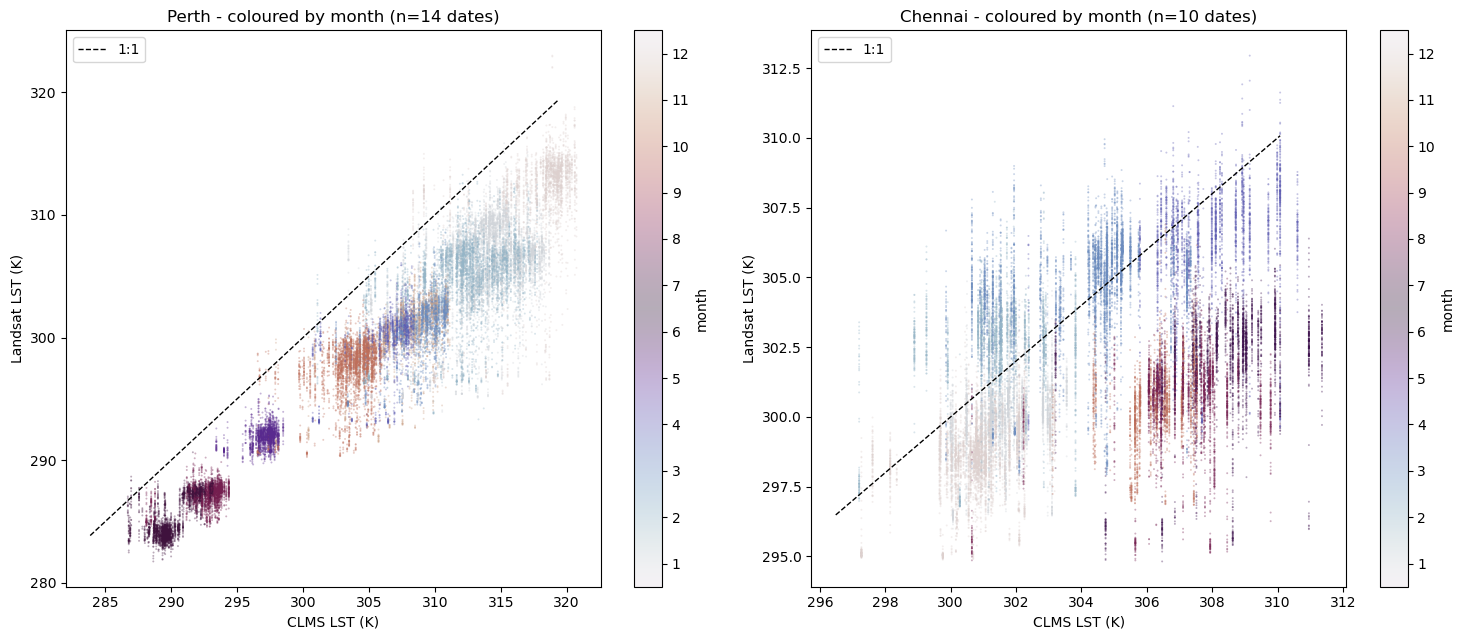

In [43]:
SEASON_CITIES = ["Perth", "Chennai"]  # the two V-shaped scatters
SEASON_SAMPLE = 30_000  # points drawn per panel, for legibility

avail = [c for c in SEASON_CITIES if city_results.get(c, {}).get("status") == "ok"]
fig, axes = plt.subplots(1, len(avail), figsize=(7.5 * len(avail), 6.5), squeeze=False)
for ax, cname in zip(axes[0], avail):
    r = city_results[cname]
    k = min(SEASON_SAMPLE, r["ls_pool"].size)
    i = np.random.default_rng(1).choice(r["ls_pool"].size, k, replace=False)
    sc = ax.scatter(
        r["cl_pool"][i],
        r["ls_pool"][i],
        c=r["mon_pool"][i],
        cmap="twilight",  # cyclic: December sits next to January
        vmin=0.5,
        vmax=12.5,
        s=2,
        alpha=0.35,
        linewidths=0,
    )
    lo_c, hi_c = np.percentile(np.concatenate([r["ls_pool"], r["cl_pool"]]), [1, 99])
    ax.plot([lo_c, hi_c], [lo_c, hi_c], "k--", lw=1, label="1:1")
    ax.set_xlabel("CLMS LST (K)")
    ax.set_ylabel("Landsat LST (K)")
    ax.set_title(f"{r['name']} - coloured by month (n={r['n_pairs']} dates)")
    ax.legend(loc="upper left")
    plt.colorbar(sc, ax=ax, label="month", ticks=range(1, 13))
plt.tight_layout()
plt.show()

The mean residual per month gives the same answer numerically: a seasonal cause shows up as a systematic shift between groups of months.

In [44]:
for cname in avail:
    r = city_results[cname]
    resid = r["ls_pool"] - r["cl_pool"]
    print(f"{r['name']}: mean residual by month")
    for mth in range(1, 13):
        sel = r["mon_pool"] == mth
        if sel.sum():
            print(f"    {mth:>2}  {resid[sel].mean():+7.2f} K   ({sel.sum():>6} px)")

Perth: mean residual by month
     1    -7.89 K   ( 26266 px)
     2    -7.58 K   ( 26510 px)
     3    -7.92 K   ( 13032 px)
     4    -6.58 K   (  8190 px)
     5    -5.15 K   (  9513 px)
     7    -4.91 K   ( 15211 px)
     8    -5.57 K   ( 10625 px)
    10    -6.13 K   ( 17825 px)
    11    -7.31 K   (  9879 px)
    12    -6.48 K   ( 12949 px)
Chennai: mean residual by month
     1    -1.76 K   ( 17295 px)
     2    +0.95 K   ( 17482 px)
     3    +0.57 K   ( 28528 px)
     4    -1.75 K   ( 15174 px)
     6    -6.31 K   ( 17504 px)
     8    -6.41 K   ( 17544 px)
    10    -5.80 K   ( 11972 px)
    12    -2.16 K   ( 24501 px)


### 11.5 What the diagnostics say

- **Per-date vs pooled slope (11.1):** the per-date median slopes range from 0.26 (Alicante) to 0.78 (Brasilia). Pooling all dates inflates the slope in most cities, strongly in Istanbul (1.03 pooled vs 0.43 per date), Seoul (0.99 vs 0.27) and Alicante (0.93 vs 0.26): the pooled slope mostly measures the seasonal cycle, which both products see in the same way, not the spatial pattern within a date. Pooled and per-date slopes agree in Brasilia, Nairobi and Chennai. Within a date the slopes are clearly below 1 in every city.
- **Dilution (11.2):** no sign of it. The slope is the same at 100 m and 300 m (as expected, since both sample the same 3 km CLMS field), and it hardly changes from the 22 km to the 60 km box: Chicago 0.88 → 0.88, Brasilia 0.84 → 0.85, Nairobi 0.78 → 0.80, London 0.94 → 0.90. London has no 22 km / 100 m value because it failed the Part 3 thresholds, but it passes the relaxed diagnostic ones. Even in Nairobi, where the spread of CLMS grows from 3.5 to 4.9 K with the larger box, the slope stays at 0.8. One limitation: these slopes and std devs are pooled over all dates, so they are dominated by the seasonal cycle (a CLMS std dev of 11-12 K in London and Chicago is mostly seasonal, not spatial). The test shows that the pooled slope is not diluted; it cannot rule out dilution of the per-date slopes of Section 11.1, where the spatial variance within one date is much smaller.
- **Decomposition (11.3):** it depends on the city, and on how much of a seasonal cycle it has. In London and Chicago the correlation is very high (r = 0.97) and constant, and the slope is below 1 because Landsat's amplitude is 5-10 % smaller than that of CLMS (sd_L/sd_C = 0.91-0.96). This is the radiometric effect: top-of-atmosphere brightness temperature compresses the range of surface temperatures. In Nairobi it is the other way round: Landsat's amplitude is as large as or larger than that of CLMS (1.01-1.14), and the slope is below 1 only because of the weaker correlation (r = 0.70-0.79). Brasilia is in between. In Nairobi r rises with the larger box, as dilution predicts, but the amplitude ratio falls at the same time, so the slope stays the same. Note that `n` differs between the rows of London, Chicago and Nairobi, so those rows do not use the same dates, and that the pools are again dominated by the seasonal cycle.
- **V-shapes (11.4):** seasonal, in both cities, but in different ways.
  - **Chennai** shows two clearly separate branches, and they separate by colour. The January-April dates lie along the 1:1 line (mean residual about +0.6 to +1.0 K in February-March). The June-October dates lie 5-6 K below it (-5.8 to -6.4 K). This is the V, and it is a seasonal regime, not a coastal effect. It explains Chennai's low pooled slope (0.38, R² 0.17) and its large between-date spread of the bias (2.75 K). A few scattered very cold Landsat pixels (295-297 K), mostly on the June-October dates, may be cloud edges that survived the mask (cause 3).
  - **Perth** shows no two separate branches once coloured by month. Each date forms a compact cluster, and the clusters line up along one band below the 1:1 line. The distance from the line grows from about 5 K in winter (-4.9 to -5.6 K in July-August) to about 8 K in summer (-7.5 to -7.9 K in January-March). The seasonal shift of the bias therefore shows up as a pooled slope below 1 (0.87), not as a V. A thin tail of cold Landsat pixels on some summer dates may be the coastal effect (cause 1), but it is minor.

  Within one city, the bias therefore follows the season, even though the ordering between cities did not follow the expected water-vapour pattern (Section 10.6).

**Implication for the additive model.** Within a date, Landsat reproduces only part of the 3 km variation of CLMS in every city (per-date slopes 0.26-0.78), and neither a finer resolution nor a larger box brings the pooled slope to 1. Part of this is a genuine difference in amplitude between the two products, and part is decorrelation. In addition, the Landsat-CLMS bias shifts with the season by several Kelvin in some cities. Both effects predict that the error of a sharpened map grows with the temperature difference between the calibration and target dates, and that a calibration scene from the same season is needed. Part 5 measures that growth directly, instead of inferring it from a regression.

# Part 5 - Error budget

## 12. Leave-one-date-out validation

Parts 2-4 test the sharpening assumption indirectly. The direct test is to calibrate on one date, sharpen another date on which Landsat also observed the city, and compare the result with what Landsat actually saw. The calibration pairs already fetched provide this for free. For any two dates *i* (calibration) and *j* (target), the sharpened field `CLMS_j + residual_i` is a prediction of `Landsat_j`, so its per-pixel error is `residual_j - residual_i`. No information from Landsat on date *j* enters the prediction.

We split the error in two:

- **Pattern error** - the spatial RMSE of the error after removing its scene mean. This is the accuracy of the fine-scale structure that the sharpening adds, independent of any offset choice.
- **Mean error (bias drift)** - the scene mean of the error, i.e. how much the Landsat-CLMS offset changed between the two dates. It only matters if the offset is not re-measured, e.g. when sharpening onto the Landsat scale with a fixed offset. With `bias_offset = -mean(residual)`, as in Part 1, the scene mean of the sharpened map follows CLMS by construction.

Both are compared with a **no-sharpening baseline**: `CLMS_j` plus a constant offset. The pattern error of the baseline is simply the spatial std dev of `residual_j`, i.e. the fine-scale structure that 3 km CLMS misses. The **skill** `1 - pattern / baseline` is the fraction of that missing structure recovered by the sharpening: 0 means no better than plain CLMS, 1 means perfect, and a negative value means worse than not sharpening at all.

**Limitations.** The reference is Landsat top-of-atmosphere LST at 100 m, so errors of the Landsat retrieval itself are not included. Only clear-sky overpass hours can be evaluated; the error at other hours of the day, when the thermal contrast between surfaces differs, is not covered by this test.

### 12.1 Validation functions

`cross_validate()` returns one row per ordered (calibration, target) pair of dates. `cv_summary()` reduces those rows to medians and to the skill score.

In [45]:
def cross_validate(stack, dates, clms_means):
    """Leave-one-date-out validation of the sharpening from a stack of residuals.

    Calibrating on date i and sharpening date j predicts Landsat_j as
    CLMS_j + residual_i, so the per-pixel error is residual_j - residual_i.
    """
    t = [dtparser.isoparse(d) for d in dates]
    rows = []
    for i in range(len(stack)):
        for j in range(len(stack)):
            if i == j:
                continue
            err = stack[j] - stack[i]
            m = np.isfinite(err)
            if m.sum() < 100:
                continue
            rows.append(
                {
                    "pattern_rmse": float(np.std(err[m])),
                    "baseline_rmse": float(np.std(stack[j][m])),
                    "mean_error": float(np.mean(err[m])),
                    "days": abs((t[j] - t[i]).days),
                    "dT": clms_means[j] - clms_means[i],
                }
            )
    return rows


def cv_summary(rows):
    """Medians over all (calibration, target) pairs of a cross_validate() result."""
    pattern = float(np.median([r["pattern_rmse"] for r in rows]))
    baseline = float(np.median([r["baseline_rmse"] for r in rows]))
    return {
        "pattern_rmse": pattern,
        "baseline_rmse": baseline,
        "skill": 1 - pattern / baseline,
        "bias_drift_sd": float(np.std([r["mean_error"] for r in rows])),
        "n_combinations": len(rows),
    }

### 12.2 Budapest

With *N* usable dates, Budapest gives *N(N-1)* calibration/target combinations.

In [46]:
bud_cv = cross_validate(residual_stack, used, [np.nanmean(c) for c in clms_lsts])
bud_summary = cv_summary(bud_cv)

print(f"Budapest: {len(used)} dates -> {bud_summary['n_combinations']} combinations")
print(f"Pattern error, sharpened (median): {bud_summary['pattern_rmse']:.2f} K")
print(f"Pattern error, no sharpening:      {bud_summary['baseline_rmse']:.2f} K")
print(f"Skill (fraction of fine structure recovered): {bud_summary['skill']:.2f}")
print(f"Bias drift between dates (std dev): {bud_summary['bias_drift_sd']:.2f} K")

Budapest: 28 dates -> 756 combinations
Pattern error, sharpened (median): 1.78 K
Pattern error, no sharpening:      2.16 K
Skill (fraction of fine structure recovered): 0.18
Bias drift between dates (std dev): 2.58 K


The plots show how the pattern error depends on (a) the time between calibration and target, and (b) the difference in scene-mean CLMS temperature between the two dates. Panel (b) tests the additive-in-Kelvin assumption directly: if the relationship were not additive (Section 11), the error would grow with |ΔT|. Grey crosses show the no-sharpening baseline for the same combinations.

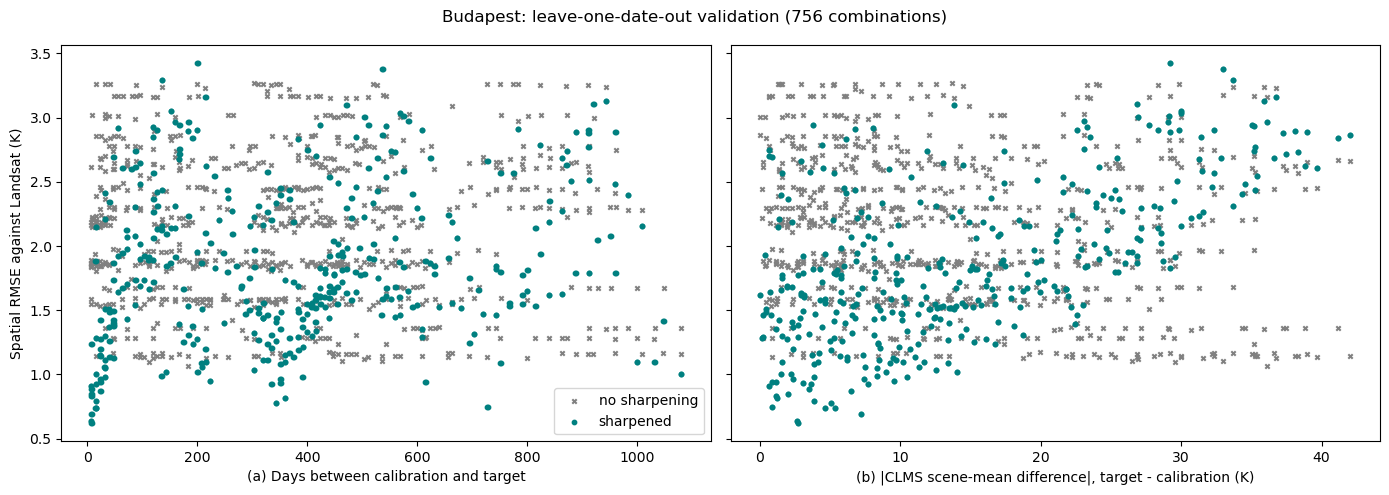

In [47]:
days = np.array([r["days"] for r in bud_cv])
abs_dT = np.abs([r["dT"] for r in bud_cv])
pattern = np.array([r["pattern_rmse"] for r in bud_cv])
baseline = np.array([r["baseline_rmse"] for r in bud_cv])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, xval, xlabel in [
    (axes[0], days, "(a) Days between calibration and target"),
    (axes[1], abs_dT, "(b) |CLMS scene-mean difference|, target - calibration (K)"),
]:
    ax.scatter(xval, baseline, s=10, marker="x", color="grey", label="no sharpening")
    ax.scatter(xval, pattern, s=10, color="teal", label="sharpened")
    ax.set_xlabel(xlabel)
axes[0].set_ylabel("Spatial RMSE against Landsat (K)")
axes[0].legend()
fig.suptitle(f"Budapest: leave-one-date-out validation ({len(bud_cv)} combinations)")
plt.tight_layout()
plt.show()

With 28 usable dates, Budapest gives 756 calibration/target combinations. The median pattern error of the sharpened maps is 1.78 K, against 2.16 K for plain CLMS, a skill of 0.18. The two panels show where this comes from:

- **Time between the dates does not matter much (a).** The error does not grow with the number of days. The lowest errors are found both for pairs less than about 20 days apart and for pairs from the same season one or more years apart. The residual pattern of the city is stable over years; what changes is the season.
- **The temperature difference does matter (b).** The error rises with |ΔT|, and above about 20 K the sharpened maps are worse than plain CLMS. Such pairs are typically a winter calibration scene applied to a summer target, or the reverse, when the fine-scale pattern itself is different (vegetation, snow, sun angle).

The additive model therefore works within a season but not across seasons. Section 12.4 tests whether a different model can do better, and the bands of |ΔT| used there (<10 K, 10-20 K, >20 K) follow from this plot.

### 12.3 All cities

The same validation for every city of Part 3, using the residual stacks kept by `summarise_city()`. The chart compares the pattern error of the sharpened maps with the no-sharpening baseline per city.

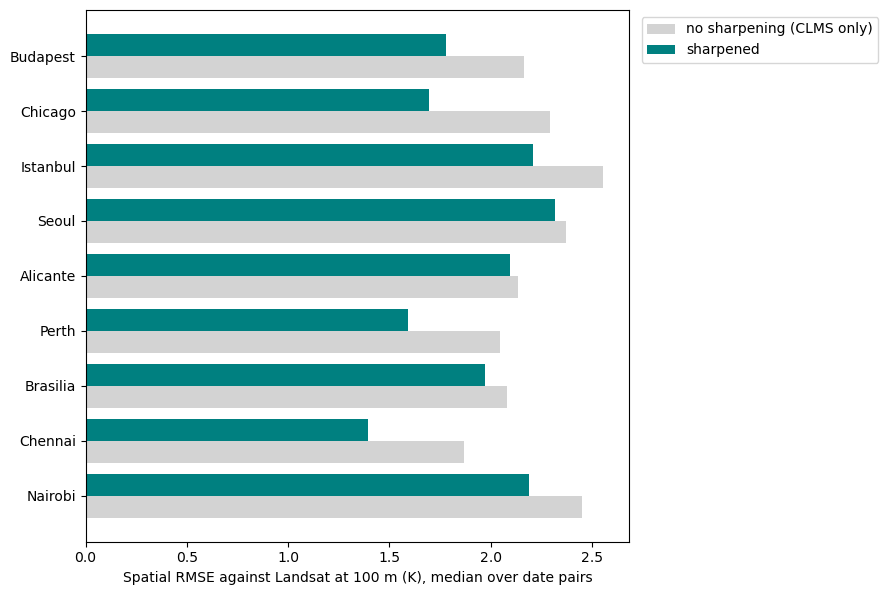

In [48]:
for r in ok:
    r["cv"] = cv_summary(
        cross_validate(r["residual_stack"], r["dates"], r["clms_means"])
    )

labels = ["Budapest"] + [r["name"] for r in ok]
summaries = [bud_summary] + [r["cv"] for r in ok]
y = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(9, 0.45 * len(labels) + 2))
ax.barh(
    y + 0.2,
    [s["baseline_rmse"] for s in summaries],
    height=0.4,
    color="lightgrey",
    label="no sharpening (CLMS only)",
)
ax.barh(
    y - 0.2,
    [s["pattern_rmse"] for s in summaries],
    height=0.4,
    color="teal",
    label="sharpened",
)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel("Spatial RMSE against Landsat at 100 m (K), median over date pairs")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))  # outside, so no bar is hidden
plt.tight_layout()
plt.show()

The sharpened maps are closer to Landsat than plain CLMS in all nine cities that passed the thresholds of Part 3 (London and Novosibirsk did not). The gain differs a lot between cities: the skill ranges from 0.02 (Seoul, Alicante) to 0.26 (Chicago) and 0.25 (Chennai). Section 13 gives the numbers.

### 12.4 Can a scaled model do better? (Budapest)

Section 11.1 found that, within a single date, Landsat reproduces only part of the 3 km spatial variation of CLMS (per-date slopes well below 1), and Section 12.2 found that the error of the sharpened map grows with the temperature difference between calibration and target date. Both point to the same possible weakness: the additive model transfers the change seen by CLMS between the two dates at full strength.

Rearranging the sharpening formula makes this explicit. With `L` the Landsat LST of the calibration date and `C_cal`, `C_tgt` the two CLMS fields:

```
additive (this notebook):  sharpened = L + 1 * (C_tgt - C_cal) + bias_offset
scaled:                    sharpened = L + s * (C_tgt - C_cal) + (1 - s) * dT_mean + bias_offset
```

The factor `s` blends two assumptions: `s = 0` means "nothing has changed since the Landsat date" (the old Landsat image is used as it is), and `s = 1` means "apply the full change seen by CLMS in each 3 km cell". The term `(1 - s) * dT_mean`, with `dT_mean` the difference of the two CLMS scene means, puts back the part of the scene-mean change that `s < 1` would otherwise remove, so that the sharpened map stays on the CLMS level. It is a constant over the scene. The scaled model is still a per-pixel calculation, and the companion custom script offers it as the optional parameters `changeScale` (`s`) and `deltaTMean` (`dT_mean`).

This section compares, for every calibration/target pair of Budapest dates:

| Model | Prediction of the target Landsat field |
| --- | --- |
| plain CLMS | `C_tgt` (the no-sharpening baseline of Section 12) |
| persistence | `L` (s = 0) |
| additive | `L + (C_tgt - C_cal)` (s = 1, the method of this notebook) |
| scaled, calibration-date s | `L + s_cal * (C_tgt - C_cal)`, with `s_cal` the per-date slope of the calibration date |
| scaled, fixed s | `L + s_fix * (C_tgt - C_cal)`, with `s_fix` the median per-date slope of all *other* dates |

The fixed-s variant mimics what a Copernicus Browser user could do: set one documented value of `s` in the script. The target date is left out of its median, so no information from the target enters the prediction. As in Section 12, scene means are removed before computing the RMSE, so only the spatial pattern is compared, and the constant `dT_mean` and `bias_offset` terms drop out.

The comparison uses only the Budapest rasters already in memory: no further requests.

In [49]:
def date_slope(lls, cls_):
    """Spatial slope of Landsat on CLMS within one date (NaN if too few pixels)."""
    m = np.isfinite(lls) & np.isfinite(cls_)
    if m.sum() < 1000 or np.ptp(cls_[m]) == 0:
        return np.nan
    return linear_fit(cls_[m], lls[m])[0]


def compare_models(ls_maps, cl_maps):
    """Leave-one-date-out pattern RMSE (K) of each model, one row per date pair."""
    slopes = np.array([date_slope(a, b) for a, b in zip(ls_maps, cl_maps)])
    clms_means = [np.nanmean(c) for c in cl_maps]
    rows = []
    for i in range(len(ls_maps)):
        for j in range(len(ls_maps)):
            if i == j or not np.isfinite(slopes[i]):
                continue
            m = np.isfinite(ls_maps[i]) & np.isfinite(cl_maps[i])
            m &= np.isfinite(ls_maps[j]) & np.isfinite(cl_maps[j])
            if m.sum() < 100:
                continue
            L_cal, L_tgt, C_tgt = ls_maps[i][m], ls_maps[j][m], cl_maps[j][m]
            dC = C_tgt - cl_maps[i][m]
            s_fix = np.nanmedian(np.delete(slopes, j))  # target date left out
            rows.append(
                {
                    "dT": abs(clms_means[j] - clms_means[i]),
                    "baseline": float(np.std(L_tgt - C_tgt)),
                    "persistence": float(np.std(L_tgt - L_cal)),
                    "additive": float(np.std(L_tgt - (L_cal + dC))),
                    "scaled_cal": float(np.std(L_tgt - (L_cal + slopes[i] * dC))),
                    "scaled_fix": float(np.std(L_tgt - (L_cal + s_fix * dC))),
                }
            )
    return slopes, rows

The table gives the median pattern RMSE of each model and, in brackets, its skill against plain CLMS, for all pairs and in three bands of |ΔT| (the difference of the CLMS scene means, as in Section 12.2).

In [50]:
date_slopes, model_rows = compare_models(landsat_lsts, clms_lsts)

MODELS = [
    ("baseline", "plain CLMS"),
    ("persistence", "persistence (s = 0)"),
    ("additive", "additive (s = 1, this notebook)"),
    ("scaled_cal", "scaled, calibration-date s"),
    ("scaled_fix", "scaled, fixed s"),
]
DT_BANDS = [
    ("all", 0, np.inf),
    ("<10 K", 0, 10),
    ("10-20 K", 10, 20),
    (">20 K", 20, np.inf),
]

dT = np.array([r["dT"] for r in model_rows])
bands = [(name, (dT >= lo) & (dT < hi)) for name, lo, hi in DT_BANDS]
base = np.array([r["baseline"] for r in model_rows])

print(
    f"Per-date slopes: median {np.nanmedian(date_slopes):.2f}, "
    f"range {np.nanmin(date_slopes):.2f} to {np.nanmax(date_slopes):.2f}"
)
print(f"\n{'model':<34}" + "".join(f"{name:>16}" for name, _ in bands))
print(f"{'date pairs':<34}" + "".join(f"{sel.sum():>16}" for _, sel in bands))
print("-" * 98)
for key, label in MODELS:
    vals = np.array([r[key] for r in model_rows])
    cells = ""
    for _, sel in bands:
        if not sel.any():
            cells += f"{'-':>16}"
            continue
        rmse = np.median(vals[sel])
        skill = 1 - rmse / np.median(base[sel])
        cells += f"{rmse:>9.2f} ({skill:+.2f})"
    print(f"{label:<34}{cells}")
print("-" * 98)
print("median pattern RMSE in K (skill against plain CLMS)")

Per-date slopes: median 0.54, range 0.08 to 0.82

model                                          all           <10 K         10-20 K           >20 K
date pairs                                     756             328             208             220
--------------------------------------------------------------------------------------------------
plain CLMS                             2.16 (+0.00)     2.23 (+0.00)     1.91 (+0.00)     1.89 (+0.00)
persistence (s = 0)                    1.51 (+0.30)     1.27 (+0.43)     1.49 (+0.22)     2.34 (-0.24)
additive (s = 1, this notebook)        1.78 (+0.18)     1.53 (+0.31)     1.61 (+0.16)     2.39 (-0.26)
scaled, calibration-date s             1.53 (+0.29)     1.29 (+0.42)     1.45 (+0.24)     2.22 (-0.18)
scaled, fixed s                        1.53 (+0.29)     1.29 (+0.42)     1.44 (+0.25)     2.19 (-0.16)
--------------------------------------------------------------------------------------------------
median pattern RMSE in K (skill against

The plot shows the same comparison as a function of |ΔT|: the median RMSE of each model in 5 K bands. If the scaled model fixes the weakness found in Section 12.2, its curve should stay flat where the additive curve rises.

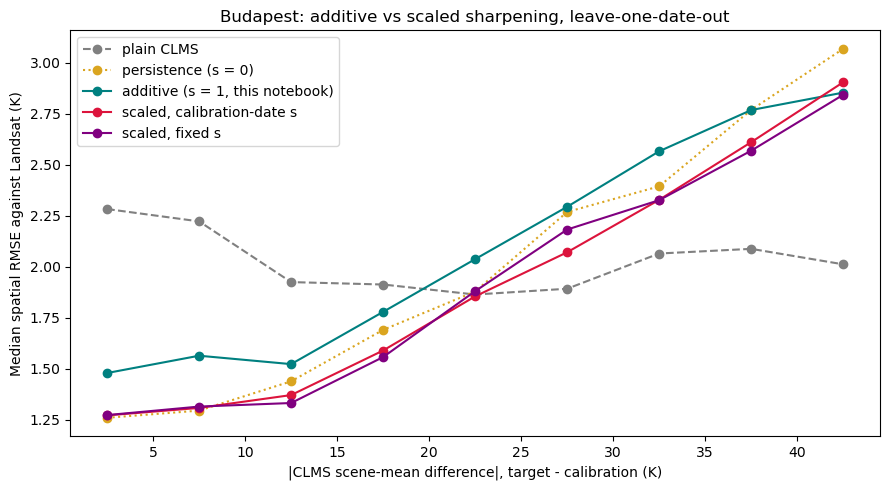

In [51]:
edges = np.arange(0, np.ceil(dT.max() / 5) * 5 + 5, 5)
centres = (edges[:-1] + edges[1:]) / 2
styles = {
    "baseline": dict(color="grey", ls="--"),
    "persistence": dict(color="goldenrod", ls=":"),
    "additive": dict(color="teal"),
    "scaled_cal": dict(color="crimson"),
    "scaled_fix": dict(color="purple"),
}

fig, ax = plt.subplots(figsize=(9, 5))
for key, label in MODELS:
    vals = np.array([r[key] for r in model_rows])
    med = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        sel = (dT >= lo) & (dT < hi)
        med.append(np.median(vals[sel]) if sel.any() else np.nan)
    ax.plot(centres, med, marker="o", label=label, **styles[key])
ax.set_xlabel("|CLMS scene-mean difference|, target - calibration (K)")
ax.set_ylabel("Median spatial RMSE against Landsat (K)")
ax.set_title("Budapest: additive vs scaled sharpening, leave-one-date-out")
ax.legend()
plt.tight_layout()
plt.show()

**Result.** Across the 28 Budapest dates the per-date slopes have a median of 0.54 (range 0.08-0.82). Both scaled variants beat the additive model in every band of |ΔT|. Over all 756 pairs the median pattern error is 1.53 K for the scaled models and 1.78 K for the additive model (skill 0.29 vs 0.18). Below 10 K it is 1.29 vs 1.53 K (skill 0.42 vs 0.31). The gain is therefore not limited to large |ΔT|; it is present within the same season too.

The fixed-s variant is as good as the calibration-date variant (1.53 vs 1.53 K overall, 2.19 vs 2.22 K above 20 K). One value of `s` per city is enough; it does not have to be measured on each calibration date.

The persistence model, which ignores CLMS altogether and uses the calibration Landsat image as it is, does as well as the scaled models: 1.51 K overall and 1.27 K below 10 K, the lowest values in the table. The scaled models are only marginally better at 10-20 K and above 20 K. In other words, in this test the change that CLMS sees between the two dates, applied cell by cell, adds more error to the fine-scale pattern than it removes. At the pattern level the Landsat image carries the detail, and CLMS mainly contributes the scene-mean level for the target hour. Above 20 K every model is worse than plain CLMS: the pattern itself has changed between the seasons, and no value of `s` fixes that.

Three caveats limit how far this can be generalised:

1. **The reference favours persistence.** The target-date "truth" is a Landsat image from the same sensor, with the same retrieval, emissivity model and viewing geometry as the calibration image. Any artefact these share is reproduced perfectly by persistence and is counted as an error for anything that brings in CLMS.
2. **One city, one small box.** The 22 km box holds only about 50 CLMS cells, so the 3 km change between the dates is estimated from few, partly noisy cells. The result has not been checked in the other cities (see below).
3. **Only the overpass hour is tested.** At other hours of the day, the 3 km change from the morning to e.g. the afternoon heat peak is a real signal that only CLMS can supply; persistence cannot reproduce it at all. This test cannot tell how much of it the sharpening should pass on.

**Sweeping `s`.** The two scaled variants use data-driven values of `s`. A Copernicus Browser user will more likely try round numbers. The sweep below repeats the comparison for fixed values of `s` from 0 (persistence) to 1 (additive), on the same date pairs as the table above, to show how sensitive the error is to the choice of `s`.

In [52]:
S_VALUES = [0, 0.25, 0.5, 0.75, 1]


def sweep_s(ls_maps, cl_maps, slopes, s_values):
    """Leave-one-date-out pattern RMSE (K) for fixed values of s, one row per date pair.

    Uses the same date pairs as compare_models() (calibration dates with a valid slope).
    """
    clms_means = [np.nanmean(c) for c in cl_maps]
    rows = []
    for i in range(len(ls_maps)):
        for j in range(len(ls_maps)):
            if i == j or not np.isfinite(slopes[i]):
                continue
            m = np.isfinite(ls_maps[i]) & np.isfinite(cl_maps[i])
            m &= np.isfinite(ls_maps[j]) & np.isfinite(cl_maps[j])
            if m.sum() < 100:
                continue
            L_cal, L_tgt, C_tgt = ls_maps[i][m], ls_maps[j][m], cl_maps[j][m]
            dC = C_tgt - cl_maps[i][m]
            row = {
                "dT": abs(clms_means[j] - clms_means[i]),
                "baseline": float(np.std(L_tgt - C_tgt)),
            }
            for s in s_values:
                row[s] = float(np.std(L_tgt - (L_cal + s * dC)))
            rows.append(row)
    return rows

The table has the same layout as the one above: median pattern RMSE and, in brackets, skill against plain CLMS, per band of |ΔT|. The last row names the value of `s` with the lowest error in each band.

In [53]:
sweep_rows = sweep_s(landsat_lsts, clms_lsts, date_slopes, S_VALUES)
dT_s = np.array([r["dT"] for r in sweep_rows])
base_s = np.array([r["baseline"] for r in sweep_rows])
sweep_bands = [(name, (dT_s >= lo) & (dT_s < hi)) for name, lo, hi in DT_BANDS]

print(f"{'s':<10}" + "".join(f"{name:>16}" for name, _ in sweep_bands))
print("-" * 74)
best = {name: (np.inf, None) for name, _ in sweep_bands}
for s in S_VALUES:
    vals = np.array([r[s] for r in sweep_rows])
    cells = ""
    for name, sel in sweep_bands:
        if not sel.any():
            cells += f"{'-':>16}"
            continue
        rmse = np.median(vals[sel])
        cells += f"{rmse:>9.2f} ({1 - rmse / np.median(base_s[sel]):+.2f})"
        if rmse < best[name][0]:
            best[name] = (rmse, s)
    print(f"{s:<10}{cells}")
print("-" * 74)
print(f"{'lowest':<10}" + "".join(f"{'s = ' + str(b[1]):>16}" for b in best.values()))
print("median pattern RMSE in K (skill against plain CLMS)")

s                      all           <10 K         10-20 K           >20 K
--------------------------------------------------------------------------
0              1.51 (+0.30)     1.27 (+0.43)     1.49 (+0.22)     2.34 (-0.24)
0.25           1.47 (+0.32)     1.22 (+0.45)     1.42 (+0.26)     2.20 (-0.17)
0.5            1.51 (+0.30)     1.28 (+0.43)     1.44 (+0.25)     2.19 (-0.16)
0.75           1.62 (+0.25)     1.37 (+0.38)     1.48 (+0.22)     2.29 (-0.21)
1              1.78 (+0.18)     1.53 (+0.31)     1.61 (+0.16)     2.39 (-0.26)
--------------------------------------------------------------------------
lowest            s = 0.25        s = 0.25        s = 0.25         s = 0.5
median pattern RMSE in K (skill against plain CLMS)


**Result of the sweep.** The lowest error is at `s = 0.25` in every band except above 20 K, where `s = 0.5` is lower by only 0.01 K. The curve is flat between `s = 0` and `s = 0.5`: over all pairs the error is 1.51, 1.47 and 1.51 K, and below 10 K it is 1.27, 1.22 and 1.28 K. Beyond 0.5 it rises steadily to the additive model at `s = 1` (1.62 K at 0.75, 1.78 K at 1). The choice of `s` within 0.25-0.5 therefore hardly matters, and the calibration-date slopes (median 0.54) fall at the upper edge of this flat range, which is why both scaled variants did well. The gain of the best `s` over persistence is small (0.04 K overall), so over Budapest essentially all of the improvement comes from damping the CLMS change, not from the exact value of `s`.

**Status of the scaled model.** The method of this notebook, and the default of the companion custom script, remains the additive model (`s = 1`), and we report openly that it was not the best model in this test. We keep it as the default for three reasons. It is the only model that passes on the full change seen by CLMS, which is the point of sharpening a product that is available every hour (caveat 3). The evidence against it comes from a single city and a reference that favours persistence (caveats 1 and 2). And it needs no extra parameter.

The scaled model is offered as an option: the custom script has the parameters `changeScale` (`s`, default 1) and `deltaTMean`, and Section 12.5 shows how to compute both for a calibration pair. To adopt it as the default, it would have to be confirmed in more cities. That requires the CLMS maps of every date, which `fetch_city_pairs()` does not keep, and hence a re-run of Part 3. It would also need an independent reference at other hours of the day, such as ground stations, to settle caveat 3.

### 12.5 Computing `s` and `deltaTMean` for your own calibration pair

To use the scaled model in the custom script, two numbers are needed besides `biasOffset`:

- **`changeScale` (`s`)** - the spatial slope of Landsat LST on CLMS LST on the calibration date, over the area of interest. It is computed with `date_slope()` from Section 12.4. It only needs the calibration pair, because the target date has no Landsat image. A single date gives a noisy slope (in Section 11.1 the per-date slopes varied by 0.1-0.2 around their median), and Section 12.4 showed that the median over several dates works as well as the slope of the calibration date. If several calibration dates are available, as in Part 2, use their median.
- **`deltaTMean`** - `mean(CLMS_TGT) - mean(CLMS_CAL)` over the area, in K. In the Copernicus Browser it can be read from the statistics panel of two plain CLMS LST layers. It is only needed when `s` is not 1.

The cell below computes both for the Part 1 calibration pair. The CLMS calibration field is not an output of the Part 1 request, but it follows from two outputs that are: `CLMS_CAL = Landsat - residual`. The cell also checks that the scaled map keeps the scene mean of the additive map, which is what `deltaTMean` is for.

In [54]:
# the calibration pair of Part 1: CLMS_CAL = Landsat - residual
ql_clms_cal = quick["landsat_lst"] - quick["residual"]
ql_s = date_slope(quick["landsat_lst"], ql_clms_cal)

ql_mask = np.isfinite(quick["residual"]) & np.isfinite(quick["clms_tgt"])
ql_delta_t = float(np.mean(quick["clms_tgt"][ql_mask] - ql_clms_cal[ql_mask]))

ql_scaled = (
    quick["landsat_lst"]
    + ql_s * (quick["clms_tgt"] - ql_clms_cal)
    + (1 - ql_s) * ql_delta_t
    + ql_bias_offset
)

print(f"Slope of the Part 1 calibration date:        {ql_s:.2f}")
print(f"Median slope of the Part 2 dates (Budapest): {np.nanmedian(date_slopes):.2f}")
print(f"Scene-mean CLMS change, target - calibration: {ql_delta_t:+.2f} K")
print(
    f"Scene mean, additive vs scaled map: {np.mean(quick['sharpened'][ql_mask]):.2f} "
    f"vs {np.mean(ql_scaled[ql_mask]):.2f} K"
)
print("\nUser options for script.js (Part 1 calibration pair):")
print(f"  var biasOffset = {ql_bias_offset:.2f};")
print(f"  var changeScale = {np.nanmedian(date_slopes):.2f};  // multi-date median")
print(f"  var deltaTMean = {ql_delta_t:.2f};")

Slope of the Part 1 calibration date:        0.89
Median slope of the Part 2 dates (Budapest): 0.54
Scene-mean CLMS change, target - calibration: +9.18 K
Scene mean, additive vs scaled map: 314.44 vs 314.44 K

User options for script.js (Part 1 calibration pair):
  var biasOffset = 2.23;
  var changeScale = 0.54;  // multi-date median
  var deltaTMean = 9.18;


**Result.** The additive and the scaled map have the same scene mean (314.44 K), as intended. The two ways of obtaining `s` differ a lot, however. The slope of the Part 1 calibration date (13 June 2025, outside the 2022-2024 window of Part 2) is 0.89, higher than on any of the 28 Part 2 dates (0.08-0.82), while their median is 0.54. According to the sweep in Section 12.4, 0.89 would give little improvement over the additive model (between 1.62 K at `s = 0.75` and 1.78 K at `s = 1`), and 0.54 most of it. A slope from a single date is therefore not a reliable choice of `s`. The printed script options use the multi-date median. Without several calibration dates, a value between 0.25 and 0.5 was the safe range over Budapest, but it has not been tested elsewhere.

Two small differences from the Copernicus Browser should be kept in mind. The Part 1 request applies the Landsat QA cloud mask, which `script.js` does not, so pixels flagged as cloud in Landsat are left out here. And the statistics panel averages each CLMS layer over the whole area, while this cell averages over pixels valid in both fields. For a clear-sky calibration scene both differences are small compared with the uncertainty of `s` itself.

## 13. Error budget

The table collects the error components measured in this notebook, per city:

- **pattern** - the spatial RMSE of a sharpened map against Landsat (Section 12), the error of the added fine-scale detail;
- **baseline** and **skill** - the same for unsharpened CLMS, and the fraction of the missing detail recovered;
- **drift sd** - the between-date std dev of the mean error, which applies only if the offset is not re-measured;
- **global offset** - the difference between the city's mean bias and the all-city mean, i.e. the extra error if one global `BIAS_OFFSET` were used instead of a local calibration (Part 3). Budapest's mean bias comes from Part 2 and is compared with the Part 3 all-city mean.

In [55]:
all_city_bias = np.mean([r["mean_bias"] for r in ok])
rows = [("Budapest", bud_summary, mean_bias)] + [
    (r["name"], r["cv"], r["mean_bias"]) for r in ok
]

print(
    f"{'City':<13}{'pattern K':>11}{'baseline K':>12}{'skill':>7}"
    f"{'drift sd K':>12}{'global offset K':>17}"
)
print("-" * 72)
for name, s, bias in rows:
    print(
        f"{name:<13}{s['pattern_rmse']:>11.2f}{s['baseline_rmse']:>12.2f}"
        f"{s['skill']:>7.2f}{s['bias_drift_sd']:>12.2f}"
        f"{abs(bias - all_city_bias):>17.2f}"
    )
print("-" * 72)

City           pattern K  baseline K  skill  drift sd K  global offset K
------------------------------------------------------------------------
Budapest            1.78        2.16   0.18        2.58             2.02
Chicago             1.70        2.29   0.26        1.65             0.26
Istanbul            2.21        2.56   0.14        1.43             0.03
Seoul               2.32        2.37   0.02        2.06             2.35
Alicante            2.10        2.13   0.02        3.42             1.18
Perth               1.59        2.05   0.22        2.17             2.81
Brasilia            1.97        2.08   0.05        2.57             0.21
Chennai             1.39        1.87   0.25        4.08             1.48
Nairobi             2.19        2.45   0.11        1.65             2.06
------------------------------------------------------------------------


Some components cannot be measured with Landsat and CLMS alone:

| Component | Size | Source |
| --- | --- | --- |
| CLMS LST retrieval uncertainty (absolute level) | bias -0.72 K, RMSD 3.36 K against 20 in-situ stations in 2025 (-0.50 K and 3.40 K for 2018-2024) | CLMS LST V3 validation report (Lopes et al., 2026) |
| Roughness constant `C` (0.005 vs 0.009) | ~0.2-0.3 K on mixed pixels | Section 2.3 |
| Landsat-CLMS time mismatch within the hourly slot | up to ~1 h; already contained in the pattern error | Section 2.2 |
| Hours other than the Landsat overpass hour | not tested | README of the custom script |

For the recommended use, with CLMS as the absolute reference and a locally measured `bias_offset`, the error of a sharpened 100 m pixel at the overpass hour of day can be approximated as

```
sigma_total ≈ sqrt(sigma_CLMS^2 + sigma_pattern^2)
```

plus the drift or global-offset term if the offset is not measured locally. With the RMSD of CLMS against in-situ stations (3.4 K) as `sigma_CLMS`, the CLMS term is larger than the pattern error of the sharpening (1.4-2.3 K). The station comparison is a point-to-pixel comparison, so part of that 3.4 K is the mismatch in scale rather than retrieval error.

**Interpretation.** The pattern error of a sharpened map is 1.4-2.3 K across the nine cities, against 1.9-2.6 K for plain CLMS. The skill is positive everywhere, but ranges from 0.26 (Chicago) and 0.25 (Chennai) down to 0.05 (Brasilia) and 0.02 (Seoul, Alicante). In Seoul and Alicante the sharpening adds almost nothing on average. These two cities also have the lowest per-date slopes in Section 11.1 (0.27 and 0.26), i.e. the weakest link between the Landsat and CLMS patterns on the same day. Brasilia does not fit this explanation (per-date slope 0.78), so the low skill has more than one cause; strong seasonality of the land surface is a likely one. These are medians over all date pairs, including pairs from different seasons: Section 12.2 showed that the error grows with |ΔT|, and in Budapest the skill is 0.31 for pairs within 10 K, against 0.18 for all pairs. Same-season calibration would probably improve the other cities in the same way.

The two offset columns are of similar size. The global offset, i.e. the error of using one all-city `BIAS_OFFSET`, is 1.7 K RMS over the cities. The per-date spread of the bias within a city (drift sd / √2) is 1.8 K RMS. A global offset therefore costs about as much as a local offset measured on a different date; at the level of about ±2 K, the bias behaves like a global constant. To bring the absolute level below that, `bias_offset` has to be measured on the calibration date itself, as in Part 1.

## 14. Conclusions

1. **The method:** Landsat-derived fine-scale residuals added to hourly CLMS LST produce 100 m LST maps for any hour with CLMS data (Part 1).
2. **Stability:** over Budapest the pattern-stability coefficient is 0.785, with a median temporal std dev of the residual of 2.1 K (Part 2). Across the eight other cities the coefficient is 0.72-0.85, so Budapest is typical (Part 3). The residual pattern is stable over years; the error of a sharpened map does not grow with the time between calibration and target (Section 12.2).
3. **Portability of the bias:** the Landsat-CLMS bias (-1.9 to -6.8 K) differs between cities by 1.6 K, the same as its variation between dates within one city (ratio 1.03). At that level of accuracy it is effectively a global constant; it does not follow the expected water-vapour ordering. For better accuracy it has to be measured on the calibration date (Parts 3 and 5).
4. **Additivity:** within a single date, Landsat reproduces only part of the 3 km spatial variation of CLMS: the per-date slopes are 0.26-0.78 across the cities (median 0.54 over Budapest), while pooling dates inflates them towards 1 (Section 11.1). In some cities the Landsat-CLMS bias also shifts with the season, by 3 K in Perth and 7 K in Chennai (Section 11.4). The error of a sharpened map grows with the temperature difference between the calibration and target dates, and above about 20 K the sharpened map is worse than plain CLMS (Sections 12.2 and 12.4).
5. **Accuracy:** the pattern error of a sharpened map is 1.4-2.3 K, and sharpening recovers 2-26 % of the fine-scale structure that plain CLMS misses, with a positive skill in all nine cities. With a calibration scene within 10 K of the target, the skill over Budapest rises to 0.31 (Part 5).
6. **Recommended use:** calibrate with a clear-sky Landsat scene from the same season and hour of day, ideally with a scene-mean temperature within 10 K of the target and not more than 20 K from it, and measure `bias_offset` locally (e.g. with `bias_offset.js` in the Copernicus Browser).
7. **Outlook:** over Budapest, damping the CLMS change between the dates lowered the pattern error from 1.78 K (`s = 1`) to 1.47-1.51 K for any `s` between 0 and 0.5, and the persistence model (`s = 0`) did almost as well as the best value (Section 12.4). A single value of `s` per city was enough. The additive model stays the default, because the test used a Landsat reference, which favours persistence, one city, and the overpass hour only; the custom script offers the scaled model as an option (Section 12.5). Adopting it as the default would need the same test in more cities and an independent reference at other hours of the day.

*Contains modified Copernicus Land Monitoring Service information (2022-2026). Landsat data courtesy of the U.S. Geological Survey.*

## How to cite

If you use this notebook or the method in your work, please cite:

> Zlinszky, A. (2026). *Landsat-sharpened CLMS Land Surface Temperature: method, validation and error budget* (Version 1.0) [Jupyter notebook]. Zenodo. https://doi.org/10.5281/zenodo.22944002

```bibtex
@software{zlinszky_2026_clms_lst_sharpening,
  author    = {Zlinszky, Andr{\'a}s},
  title     = {Landsat-sharpened {CLMS} Land Surface Temperature: method, validation and error budget},
  year      = {2026},
  version   = {1.0},
  publisher = {Zenodo},
  doi       = {10.5281/zenodo.22944002},
  url       = {https://doi.org/10.5281/zenodo.22944002}
}
```

The interactive Copernicus Browser version is the [`clms_lst_sharpening_with_landsat`](https://custom-scripts.sentinel-hub.com/data-fusion/clms_lst_sharpening_with_landsat/) custom script.

## References

- Artis, D. A., & Carnahan, W. H. (1982). Survey of emissivity variability in thermography of urban areas. *Remote Sensing of Environment*, 12(4), 313-329. https://doi.org/10.1016/0034-4257(82)90043-8
- Avdan, U., & Jovanovska, G. (2016). Algorithm for automated mapping of land surface temperature using LANDSAT 8 satellite data. *Journal of Sensors*, 2016, 1480307. https://doi.org/10.1155/2016/1480307
- Beck, H. E., Zimmermann, N. E., McVicar, T. R., Vergopolan, N., Berg, A., & Wood, E. F. (2018). Present and future Köppen-Geiger climate classification maps at 1-km resolution. *Scientific Data*, 5, 180214. https://doi.org/10.1038/sdata.2018.214
- Carlson, T. N., & Ripley, D. A. (1997). On the relation between NDVI, fractional vegetation cover, and leaf area index. *Remote Sensing of Environment*, 62(3), 241-252. https://doi.org/10.1016/S0034-4257(97)00104-1
- Jiménez-Muñoz, J. C., Sobrino, J. A., Plaza, A., Guanter, L., Moreno, J., & Martínez, P. (2009). Comparison between fractional vegetation cover retrievals from vegetation indices and spectral mixture analysis. *Sensors*, 9(2), 768-793. https://doi.org/10.3390/s90200768
- Lopes, F., Dutra, E., Ermida, S., Gomes, S., & Trigo, I. (2026). *Validation report - update 2025: Land Surface Temperature, version 3.0* (CGLOPS1_VR_LST-LST10-V3.0, Issue I1.00). Copernicus Global Land Operations. https://land.copernicus.eu/en/technical-library/validation-report-land-surface-temperature-version-3-update-2025/@@download/file
- Sobrino, J. A., & Raissouni, N. (2000). Toward remote sensing methods for land cover dynamic monitoring: application to Morocco. *International Journal of Remote Sensing*, 21(2), 353-366. https://doi.org/10.1080/014311600210876
- Sobrino, J. A., Jiménez-Muñoz, J. C., Sòria, G., Romaguera, M., Guanter, L., Moreno, J., Plaza, A., & Martínez, P. (2008). Land surface emissivity retrieval from different VNIR and TIR sensors. *IEEE Transactions on Geoscience and Remote Sensing*, 46(2), 316-327. https://doi.org/10.1109/TGRS.2007.904834
- Vachaud, G., Passerat de Silans, A., Balabanis, P., & Vauclin, M. (1985). Temporal stability of spatially measured soil water probability density function. *Soil Science Society of America Journal*, 49(4), 822-828. https://doi.org/10.2136/sssaj1985.03615995004900040006x
- Wang, F., Qin, Z., Song, C., Tu, L., Karnieli, A., & Zhao, S. (2015). An improved mono-window algorithm for land surface temperature retrieval from Landsat 8 thermal infrared sensor data. *Remote Sensing*, 7(4), 4268-4289. https://doi.org/10.3390/rs70404268
- Copernicus Land Monitoring Service: [Land Surface Temperature, global, hourly, 3 km, V3](https://land.copernicus.eu/en/products/temperature-and-reflectance/hourly-land-surface-temperature-global-v3-0-3km); [CDSE Sentinel Hub documentation of the collection](https://documentation.dataspace.copernicus.eu/APIs/SentinelHub/Data/clms/bio-geophysical-parameters/temperature-and-reflectance/land-surface-temperature/lst_global_3km_hourly_v3.html).
- Gartner, M.: [Landsat-8 land surface temperature mapping custom script](https://custom-scripts.sentinel-hub.com/landsat-8/land_surface_temperature_mapping/).